# Crop–Weed Discrimination for Precision Agriculture: Semantic Segmentation with U-Net on the CWF-788 Dataset

**Master's Project — Artificial Intelligence (IAA)**

| | |
|---|---|
| **Dataset** | [`Project-AgML/CWF788_weed_segmentation`](https://huggingface.co/datasets/Project-AgML/CWF788_weed_segmentation) (Hugging Face, AgML collection; original data: Li *et al.*, 2019) |
| **Architecture** | U-Net (Ronneberger *et al.*, 2015), implemented from scratch in PyTorch |
| **Task** | Pixel-wise semantic segmentation (task type and number of classes inferred from the data in Section 3) |
| **Environment** | Python 3.11 · Jupyter / Anaconda · PyTorch on NVIDIA CUDA or CPU (detected automatically) · Windows, Linux, macOS |

> **Execution and reporting policy.** Every number in this notebook is computed by its code cells. No result is hard-coded, assumed or copied from the literature. Markdown cells describe methodology and explain how to read outputs. Data-dependent findings are generated programmatically from the actual experiment outputs (Sections 10–15). Run the notebook from top to bottom: **Kernel → Restart & Run All**.

### Table of contents
| § | Section | § | Section |
|---|---|---|---|
| 1 | Introduction | 9 | Model Training (resumable) |
| 2 | Environment Configuration | 10 | Training Visualisation |
| 3 | Dataset Acquisition and Integrity | 11 | Test Evaluation |
| 4 | Exploratory Data Analysis | 12 | Qualitative Results and Weed-Map Derivation |
| 5 | Data Preprocessing and Partitioning | 13 | Error Analysis |
| 6 | PyTorch Dataset and DataLoader | 14 | Scientific Discussion |
| 7 | U-Net Architecture | 15 | Conclusion and Future Work |
| 8 | Loss Functions and Evaluation Metrics | | |

---
## 1. Introduction

### 1.1 Academic context
Precision agriculture aims to apply agronomic inputs (water, fertiliser, herbicide) at the right place, time and dose, rather than uniformly across a field. **Site-specific weed management (SSWM)** is among its most valuable applications. Weeds compete with crops for light, water and nutrients. Blanket herbicide spraying, the dominant control method, is costly, raises environmental and regulatory concerns, and accelerates herbicide resistance. Robotic weeders and targeted sprayers need a perception module that tells crop from weed **at pixel level** in real time. Semantic segmentation with convolutional neural networks (CNNs) has become the reference approach for this perception problem.

### 1.2 Problem statement
In early-season **transplanted vegetable fields** with no herbicide treatment, weed pressure can be extreme. Grasses and broad-leaf weeds surround and overlap the crop and share its colour, so colour indices such as Excess-Green (ExG) can separate *vegetation* from *soil* but cannot separate *crop* from *weed*. The problem studied here is learning a mapping

$$f_\theta : \mathbb{R}^{H\times W\times 3} \rightarrow \{0,\dots,K-1\}^{H\times W}$$

that assigns every pixel of an RGB field image to its semantic class, using a U-Net trained on the CWF-788 dataset.

> **Label semantics: an explicit verification step.** CWF-788 ("*Crop in Weedy Field*", Li *et al.*, 2019) was released by its authors with labels in which **the crop (cauliflower) region is annotated**. Weeds and soil together form the background. The Hugging Face collection lists it under *weed segmentation*, i.e. the crop–weed discrimination task family. This notebook does **not** assume an encoding. Section 3.5 infers the classes from the masks and Section 4 confirms them visually. When the masks are binary (crop vs. weed + soil), the learned crop mask is exactly what a weeding system needs: the crop is the region to protect, and in a weedy field **any vegetation outside it is weed**. Section 12.3 puts this into practice by deriving explicit weed maps from the U-Net crop mask and a vegetation index.

### 1.3 Research objectives
- **RO1 — Characterise the data:** schema, integrity, image geometry, label encoding, class imbalance and illumination variability.
- **RO2 — Leakage-free pipeline:** respect the authors' official train/validation/test partition, audit it for duplicates, and fit all data-dependent preprocessing (normalisation statistics) on the training split only.
- **RO3 — Model:** implement U-Net from first principles and train it with a hybrid BCE + Dice objective under a reproducible, interruption-safe protocol.
- **RO4 — Rigorous evaluation:** report region metrics (Dice, IoU, precision, recall, F1, pixel accuracy) and boundary metrics on the untouched test split, at the native annotation resolution, against an experimentally evaluated non-learned colour-index baseline.
- **RO5 — Analysis:** characterise false positives and negatives, boundary errors, small plants, class imbalance and sensitivity to illumination, and derive weed maps for agronomic use.

### 1.4 Scientific motivation
Three properties of the problem motivate the methodology:
1. **Visual similarity of crop and weeds.** Both are green and often touch or overlap, so discrimination must rely on shape, texture and context (leaf morphology, plant structure). Hierarchical convolutional features capture these cues well.
2. **Class imbalance.** The crop typically covers a small fraction of each image (quantified in Section 4). Plain pixel-wise cross-entropy is dominated by the background. The **Dice loss** (Milletari *et al.*, 2016) optimises region overlap directly and is far less sensitive to imbalance.
3. **Small dataset.** With hundreds rather than thousands of images, an architecture that is data-efficient and preserves spatial detail is required. U-Net was designed for exactly this regime. Its skip connections carry high-resolution encoder features to the decoder, which is essential for accurate leaf boundaries. Strong data augmentation is the second ingredient.

### 1.5 Proposed methodology
```
Hugging Face dataset ─► schema inspection & integrity scan ─► label-encoding inference ─► EDA
      ─► official split (+ duplicate/leakage audit) ─► train-only normalisation statistics
      ─► joint geometric augmentation (image + mask, nearest-neighbour for masks) + photometric (image only)
      ─► U-Net (4-level encoder–decoder, skip connections) ─► BCE + Dice, AdamW, ReduceLROnPlateau,
         early stopping, AMP on GPU, per-epoch checkpoints with exact resume
      ─► native-resolution test evaluation + ExG/Otsu baseline + validation-calibrated threshold
      ─► qualitative results, weed-map derivation, error analysis (FP/FN, boundary, size, imbalance, illumination)
```

### 1.6 Expected contributions
1. A **fully reproducible, resumable** U-Net pipeline for crop–weed segmentation that runs unmodified on CPU or NVIDIA GPU, under Windows or Linux.
2. A **transparent audit** of the CWF-788 data as distributed on Hugging Face: schema, encoding, integrity, duplicates and class balance.
3. A **multi-faceted evaluation protocol** covering region metrics, boundary IoU, per-image distributions, threshold calibration, a learned-vs-heuristic comparison and an illumination robustness study.
4. A **crop-to-weed map derivation** that turns crop segmentation into actionable weed-coverage estimates, together with a measurable crop-protection error.

### 1.7 Key references
- Ronneberger, O., Fischer, P., Brox, T. (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation.* MICCAI, LNCS 9351, 234–241.
- Li, N., Zhang, X., Zhang, C., Guo, H., Sun, Z., Wu, X. (2019). *Real-time crop recognition in transplanted fields with prominent weed growth: a visual-attention-based approach.* IEEE Access, 7, 185310–185321. DOI: 10.1109/ACCESS.2019.2942158.
- Milletari, F., Navab, N., Ahmadi, S.-A. (2016). *V-Net: Fully Convolutional Neural Networks for Volumetric Medical Image Segmentation.* 3DV.
- Long, J., Shelhamer, E., Darrell, T. (2015). *Fully Convolutional Networks for Semantic Segmentation.* CVPR.
- Ioffe, S., Szegedy, C. (2015). *Batch Normalization.* ICML.
- He, K., Zhang, X., Ren, S., Sun, J. (2015). *Delving Deep into Rectifiers.* ICCV.
- Loshchilov, I., Hutter, F. (2019). *Decoupled Weight Decay Regularization.* ICLR.
- Woebbecke, D. M., Meyer, G. E., Von Bargen, K., Mortensen, D. A. (1995). *Color indices for weed identification under various soil, residue, and lighting conditions.* Transactions of the ASAE, 38(1), 259–269.
- Otsu, N. (1979). *A threshold selection method from gray-level histograms.* IEEE Trans. Systems, Man, and Cybernetics, 9(1), 62–66.
- Cheng, B., Girshick, R., Dollár, P., Berg, A. C., Kirillov, A. (2021). *Boundary IoU: Improving Object-Centric Image Segmentation Evaluation.* CVPR.

---
## 2. Environment Configuration

This section verifies dependencies, imports libraries, fixes all random seeds, detects the compute device, reports software and hardware versions, and defines one experiment configuration object. Every later cell reads its hyper-parameters from this object.

### 2.1 Dependency verification
Required packages are checked **before** any heavy import. If a package is missing or older than the tested minimum, the cell stops with an explicit installation command instead of failing later with an obscure error.

In [1]:
# 2.1 Dependency verification (standard library only) -------------------------
import sys
import re
import importlib.util
import importlib.metadata as ilm

REQUIRED = {  # import name: (distribution name, minimum tested version)
    "torch": ("torch", "2.3"),
    "torchvision": ("torchvision", "0.18"),
    "datasets": ("datasets", "2.16"),
    "numpy": ("numpy", "1.24"),
    "pandas": ("pandas", "2.0"),
    "matplotlib": ("matplotlib", "3.7"),
    "PIL": ("pillow", "10.0"),
    "tqdm": ("tqdm", "4.65"),
}
OPTIONAL = {"ipywidgets": ("ipywidgets", "8.0")}  # graphical progress bars in Jupyter


def _version_tuple(version: str) -> tuple:
    """'2.5.1+cu124' -> (2, 5, 1). Robust to local version suffixes."""
    parts = []
    for token in version.split(".")[:3]:
        match = re.match(r"\d+", token)
        if match is None:
            break
        parts.append(int(match.group()))
    return tuple(parts)


problems, report = [], []
for module, (dist, minimum) in {**REQUIRED, **OPTIONAL}.items():
    optional = module in OPTIONAL
    if importlib.util.find_spec(module) is None:
        report.append((dist, "MISSING", minimum, "optional" if optional else "required"))
        if not optional:
            problems.append(dist)
        continue
    try:
        installed = ilm.version(dist)
    except ilm.PackageNotFoundError:
        installed = "unknown"
    ok = installed == "unknown" or _version_tuple(installed) >= _version_tuple(minimum)
    report.append((dist, installed, minimum, "ok" if ok else "TOO OLD"))
    if not ok and not optional:
        problems.append(f"{dist}>={minimum}")

print(f"Python {sys.version.split()[0]} (tested on 3.11)")
if sys.version_info < (3, 10):
    raise RuntimeError("Python >= 3.10 is required (the notebook uses PEP 604 type hints).")
print(f"{'package':<14}{'installed':<22}{'minimum':<10}status")
for dist, installed, minimum, status in report:
    print(f"{dist:<14}{installed:<22}{minimum:<10}{status}")

if problems:
    raise ImportError(
        "Missing or outdated packages: " + ", ".join(problems) + "\n"
        "Install them in the active environment, e.g.\n"
        "    pip install -r requirements.txt\n"
        "For an NVIDIA GPU, install the CUDA build of PyTorch first (see README.md), e.g.\n"
        "    pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124"
    )
print("\nAll required packages are available.")

Python 3.13.16 (tested on 3.11)
package       installed             minimum   status
torch         2.11.0+cu130          2.3       ok
torchvision   0.26.0+cu130          0.18      ok
datasets      4.8.5                 2.16      ok
numpy         2.1.3                 1.24      ok
pandas        2.3.3                 2.0       ok
matplotlib    3.10.0                3.7       ok
pillow        13.0.0                10.0      ok
tqdm          4.67.3                4.65      ok
ipywidgets    8.1.5                 8.0       ok

All required packages are available.


### 2.2 Library imports
Only mainstream, actively maintained libraries are used. Image augmentation uses `torchvision.transforms.v2.functional`, the current non-deprecated API, so no extra augmentation library is needed. Model summaries and FLOP counts use PyTorch's built-in tools (`torch.utils.flop_counter`).

In [2]:
# 2.2 Imports -------------------------------------------------------------------
import os
import io
import gc
import json
import math
import time
import random
import hashlib
import platform
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image, ImageFile, UnidentifiedImageError

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import InterpolationMode
import torchvision.transforms.v2.functional as TF
from torch.utils.flop_counter import FlopCounterMode

import datasets as hfds
from datasets import load_dataset, concatenate_datasets
from tqdm.auto import tqdm
from IPython.display import display, Markdown

%matplotlib inline

# Truncated or corrupted image files must raise an error so that the integrity scan can detect them.
ImageFile.LOAD_TRUNCATED_IMAGES = False
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Figure style: thin marks, recessive axes, consistent colours (train / validation / test).
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # categorical order, never cycled
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CROP_RGB = (235, 104, 52)       # predicted / annotated crop fill in overlays
GT_RGB = (42, 120, 214)         # ground-truth contour in overlays
TP_RGB, FP_RGB, FN_RGB = (27, 175, 122), (227, 73, 72), (42, 120, 214)  # error maps
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "normal", "axes.labelsize": 10,
    "axes.labelcolor": INK_2, "axes.edgecolor": "#b5b3ad", "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False, "lines.linewidth": 1.8, "lines.markersize": 5,
})
print("Imports completed.")

Imports completed.


### 2.3 Reproducibility
All pseudo-random generators (Python, NumPy, PyTorch CPU and CUDA) are seeded. cuDNN autotuning is disabled and deterministic kernels are requested. `warn_only=True` keeps the notebook running on GPU operations that have no deterministic implementation; PyTorch then emits a warning instead of an error. During training, the generators are **re-seeded at the start of every epoch** with `seed + epoch`. Shuffling and augmentation for epoch *e* are therefore identical whether training ran uninterrupted or was resumed from a checkpoint.

In [3]:
# 2.3 Reproducibility -----------------------------------------------------------
SEED = 42
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic cuBLAS (CUDA >= 10.2)


def set_seed(seed: int) -> None:
    """Seed Python, NumPy and PyTorch (CPU + all CUDA devices)."""
    random.seed(seed)
    np.random.seed(seed % 2**32)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id: int) -> None:
    """Derive NumPy/Python seeds of each DataLoader worker from PyTorch's per-worker seed."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
print(f"Global seed = {SEED}; deterministic algorithms requested (warn_only=True).")

Global seed = 42; deterministic algorithms requested (warn_only=True).


### 2.4 Compute device detection
The notebook uses an NVIDIA GPU when CUDA is available and falls back to the CPU otherwise. Several defaults in the configuration (batch size, network width, mixed precision) adapt to the detected device, so the experiment stays tractable on a laptop CPU.

In [4]:
# 2.4 Device detection and hardware report ---------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"

print(f"Selected device : {DEVICE}")
print(f"Operating system: {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Logical CPUs    : {os.cpu_count()}")
if USE_CUDA:
    props = torch.cuda.get_device_properties(0)
    free_b, total_b = torch.cuda.mem_get_info(0)
    print(f"GPU             : {props.name} (compute capability {props.major}.{props.minor})")
    print(f"GPU memory      : {total_b / 1024**3:.2f} GiB total, {free_b / 1024**3:.2f} GiB free")
    print(f"GPU count       : {torch.cuda.device_count()}")
    print(f"CUDA (PyTorch)  : {torch.version.cuda}; cuDNN {torch.backends.cudnn.version()}")
else:
    print("No CUDA-capable GPU detected: running on CPU. Defaults below adapt (narrower U-Net,"
          " smaller batch, no mixed precision). Training will be slower but fully functional.")

Selected device : cuda
Operating system: Linux 6.18.55+ (x86_64)
Logical CPUs    : 4
GPU             : Tesla T4 (compute capability 7.5)
GPU memory      : 14.56 GiB total, 14.46 GiB free
GPU count       : 2
CUDA (PyTorch)  : 13.0; cuDNN 92700


### 2.5 Software versions
Recorded for the reproducibility appendix of the report.

In [5]:
# 2.5 Software versions -----------------------------------------------------------
import PIL
import tqdm as _tqdm_pkg

versions = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "datasets": hfds.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": PIL.__version__,
    "tqdm": _tqdm_pkg.__version__,
    "cuda (torch build)": torch.version.cuda or "none (CPU build)",
    "cudnn": str(torch.backends.cudnn.version()) if USE_CUDA else "n/a",
}
display(pd.DataFrame(versions.items(), columns=["component", "version"]).set_index("component"))

,version
component,
python,3.13.16
platform,Linux-6.18.55+-x86_64-with-glibc2.39
torch,2.11.0+cu130
torchvision,0.26.0+cu130
datasets,4.8.5
numpy,2.1.3
pandas,2.3.3
matplotlib,3.10.0
pillow,13.0.0


### 2.6 Experiment configuration
All hyper-parameters are declared in a single `Config` dataclass. The resolved configuration is written to `results/<run_name>/config.json` and stored inside every checkpoint. Notes on the main choices:
- **Input size 288 × 384 (H × W).** The native images are 400 × 300 (W × H; verified in Section 3). 288 × 384 keeps the 4 : 3 aspect ratio, avoiding anisotropic distortion of leaf shapes, and both sides are divisible by $2^4 = 16$, as required by the four pooling stages of U-Net.
- **Network width.** `base_filters = 64` reproduces the original U-Net (64 → 1024 channels, ≈31 M parameters) and is the default on GPU. On CPU the default is 32 (≈7.8 M parameters, about 4× fewer FLOPs) so that training finishes in hours rather than days. Set it explicitly to compare configurations.
- **Epochs.** Configurable (recommended 20–50); early stopping on validation Dice usually ends training earlier.
- **`num_workers`.** On Windows and macOS, Python starts DataLoader workers with *spawn*. Workers cannot then import classes defined inside a notebook, so `num_workers = 0` is used there for safety. On Linux (*fork*), up to 4 workers are used.

In [6]:
# 2.6 Experiment configuration ----------------------------------------------------
@dataclass
class Config:
    # ---- Data -------------------------------------------------------------------
    dataset_id: str = "Project-AgML/CWF788_weed_segmentation"
    dataset_revision: str | None = None     # pin a commit hash for strict reproducibility
    hf_cache_dir: str | None = None         # None -> default Hugging Face cache (~/.cache/huggingface)
    img_height: int = 288                   # native 300 -> 288 (4:3 kept, divisible by 16)
    img_width: int = 384                    # native 400 -> 384
    class_names: tuple = ("background (soil + weeds)", "crop (cauliflower)")  # per dataset documentation
    fallback_val_fraction: float = 0.15     # only used if no official validation split exists
    fallback_test_fraction: float = 0.15    # only used if no official test split exists
    # ---- Augmentation (training split only) -------------------------------------
    hflip_p: float = 0.5
    vflip_p: float = 0.5                    # top-down field imagery has no canonical "up"
    rotation_degrees: float = 15.0
    brightness: float = 0.2                 # factor ~ U[1 - b, 1 + b]
    contrast: float = 0.2                   # factor ~ U[1 - c, 1 + c]
    # ---- Model --------------------------------------------------------------------
    base_filters: int = 64 if USE_CUDA else 32
    unet_depth: int = 4                     # number of 2x down-sampling stages (original U-Net: 4)
    use_batchnorm: bool = True
    # ---- Optimisation -------------------------------------------------------------
    num_epochs: int = 40                    # recommended range: 20-50
    batch_size: int = 8 if USE_CUDA else 4
    learning_rate: float = 3e-4
    weight_decay: float = 1e-4
    bce_weight: float = 0.5                 # weight of the pixel-wise term (BCE or CE)
    dice_weight: float = 0.5                # weight of the soft Dice term
    scheduler_factor: float = 0.5
    scheduler_patience: int = 4
    min_lr: float = 1e-6
    early_stopping_patience: int = 10
    early_stopping_min_delta: float = 1e-4
    use_amp: bool = USE_CUDA                # automatic mixed precision (NVIDIA GPUs only)
    threshold: float = 0.5                  # binary decision threshold, fixed a priori
    # ---- Runtime --------------------------------------------------------------------
    num_workers: int = 0 if platform.system() in ("Windows", "Darwin") else min(4, os.cpu_count() or 1)
    seed: int = SEED
    resume: bool = True                     # continue from checkpoints/<run_name>/last.pt if it exists
    run_name: str = "unet_cwf788"
    project_root: str = "."
    # ---- Analysis ---------------------------------------------------------------------
    boundary_width_fraction: float = 0.02   # Boundary IoU band d = 2% of image diagonal (Cheng et al., 2021)
    weed_map_crop_margin_px: int = 2        # safety margin around predicted crop in weed maps
    run_robustness_study: bool = True
    brightness_factors: tuple = (0.5, 0.7, 0.85, 1.0, 1.15, 1.3, 1.5)
    n_qualitative: int = 3                  # examples per group (best / median / worst)


CFG = Config()
display(pd.DataFrame(asdict(CFG).items(), columns=["parameter", "value"]).set_index("parameter"))

,value
parameter,
dataset_id,Project-AgML/CWF788_weed_segmentation
dataset_revision,None
hf_cache_dir,None
img_height,288
img_width,384
class_names,"(background (soil + weeds), crop (cauliflower))"
fallback_val_fraction,0.15
fallback_test_fraction,0.15
hflip_p,0.5


### 2.7 Project directories
Outputs are written under one folder per `run_name`:
`checkpoints/<run>/` (`last.pt`, `best.pt`), `results/<run>/` (tables, JSON, CSV) and `figures/<run>/` (charts as PNG, photographic panels as JPEG, 150 dpi).

In [7]:
# 2.7 Directories, paths and configuration sanity checks ---------------------------
ROOT = Path(CFG.project_root).resolve()
CKPT_DIR = ROOT / "checkpoints" / CFG.run_name
RESULTS_DIR = ROOT / "results" / CFG.run_name
FIG_DIR = ROOT / "figures" / CFG.run_name
for directory in (CKPT_DIR, RESULTS_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)
LAST_CKPT = CKPT_DIR / "last.pt"
BEST_CKPT = CKPT_DIR / "best.pt"
AMP_ENABLED = bool(CFG.use_amp and USE_CUDA)

if not 20 <= CFG.num_epochs <= 50:
    warnings.warn(f"num_epochs={CFG.num_epochs} is outside the recommended 20-50 range.")
stride = 2 ** CFG.unet_depth
if CFG.img_height % stride or CFG.img_width % stride:
    warnings.warn(f"Input size is not divisible by {stride}; the U-Net will pad internally.")
if CFG.bce_weight < 0 or CFG.dice_weight < 0 or CFG.bce_weight + CFG.dice_weight == 0:
    raise ValueError("Loss weights must be non-negative and not both zero.")

_ = (RESULTS_DIR / "config.json").write_text(json.dumps(asdict(CFG), indent=2))
_ = (RESULTS_DIR / "software_versions.json").write_text(json.dumps(versions, indent=2))


def save_fig(fig, name: str, photo: bool = False) -> Path:
    """Save a figure to figures/<run>/. Charts -> PNG (lossless); photo grids -> JPEG (compact)."""
    if photo:
        path = FIG_DIR / f"{name}.jpg"
        fig.savefig(path, bbox_inches="tight", facecolor="white", pil_kwargs={"quality": 90})
    else:
        path = FIG_DIR / f"{name}.png"
        fig.savefig(path, bbox_inches="tight", facecolor="white")
    return path


def df_to_markdown(df: pd.DataFrame, floatfmt: str = ".4f") -> str:
    """Render a DataFrame as a GitHub-flavoured Markdown table (no extra dependency)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, row in df.iterrows():
        cells = [f"{v:{floatfmt}}" if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v)
                 for v in row]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


print(f"Project root : {ROOT}")
print(f"Checkpoints  : {CKPT_DIR}")
print(f"Results      : {RESULTS_DIR}")
print(f"Figures      : {FIG_DIR}")
print(f"Mixed precision (AMP): {AMP_ENABLED}")

Project root : /kaggle/working
Checkpoints  : /kaggle/working/checkpoints/unet_cwf788
Results      : /kaggle/working/results/unet_cwf788
Figures      : /kaggle/working/figures/unet_cwf788
Mixed precision (AMP): True


---
## 3. Dataset Acquisition and Integrity

### 3.1 Loading the dataset
`load_dataset` downloads the Parquet files once and caches them locally (by default in `~/.cache/huggingface`). Later executions, including new kernel sessions, read from the cache without downloading again. To work fully offline after the first download, set the environment variable `HF_HUB_OFFLINE=1` before starting Jupyter. The `globals()` guard also avoids reloading when this cell is re-run in the same session.

In [8]:
# 3.1 Load the dataset from the Hugging Face Hub (cached after the first download) ---
if "raw_dataset" not in globals():
    t0 = time.perf_counter()
    raw_dataset = load_dataset(CFG.dataset_id, revision=CFG.dataset_revision, cache_dir=CFG.hf_cache_dir)
    print(f"Dataset loaded in {time.perf_counter() - t0:.1f} s")
else:
    print("Dataset already in memory: reusing it (no re-download).")
print(raw_dataset)

README.md:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 29.5MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/788 [00:00<?, ? examples/s]

Dataset loaded in 2.0 s
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'split'],
        num_rows: 788
    })
})


### 3.2 Splits and schema
The Hub may expose one or several *splits*. When there is more than one, they are concatenated and their origin is recorded in a helper column `__hf_split__`, so that the official partition is never lost. The schema printed below is the dataset's **actual** schema. No column name is assumed.

In [11]:
# 3.2 Inspect splits and schema ------------------------------------------------------
if isinstance(raw_dataset, hfds.DatasetDict):
    hf_splits = list(raw_dataset.keys())
    display(pd.DataFrame({"hub split": hf_splits,
                          "rows": [raw_dataset[s].num_rows for s in hf_splits],
                          "columns": [", ".join(raw_dataset[s].column_names) for s in hf_splits]}))
    if len(hf_splits) == 1:
        ds_all = raw_dataset[hf_splits[0]]
    else:
        ds_all = concatenate_datasets([raw_dataset[s].add_column("__hf_split__", [s] * raw_dataset[s].num_rows)
                                       for s in hf_splits])
else:
    ds_all = raw_dataset

print(f"Total rows: {ds_all.num_rows}")
print("Features (column -> type):")
for name, feature in ds_all.features.items():
    print(f"  {name:<16} {feature}")

,hub split,rows,columns
0,train,788,"image, mask, split"


Total rows: 788
Features (column -> type):
  image            Image(mode=None, decode=True)
  mask             Image(mode=None, decode=True)
  split            Value('string')


### 3.3 Automatic identification of image, mask and split columns
Columns are identified from their **declared feature types**, not from assumed names:
1. Columns of type `datasets.Image` are candidates for the image and the mask.
2. If exactly one candidate name contains a mask-like keyword (`mask`, `label`, `annotation`, `seg`, `gt`, …), it is taken as the mask. Otherwise a **content test** is used: the mask is the image column whose decoded samples have the fewest distinct pixel values.
3. The partition column is a string or `ClassLabel` column whose name contains `split`, `subset`, `fold` or `partition`, falling back to `__hf_split__`.

In [12]:
# 3.3 Column identification -----------------------------------------------------------
MASK_KEYWORDS = ("mask", "label", "annotation", "segment", "seg", "gt", "target")
SPLIT_KEYWORDS = ("split", "subset", "fold", "partition")


def _decode_from_storage(cell) -> Image.Image:
    """Decode an Image cell read with decode=False ({'bytes': ..., 'path': ...})."""
    if cell is None:
        raise ValueError("missing value (None)")
    if isinstance(cell, Image.Image):
        return cell
    data, path = cell.get("bytes"), cell.get("path")
    if data is not None:
        img = Image.open(io.BytesIO(data))
    elif path:
        img = Image.open(path)
    else:
        raise ValueError("cell contains neither bytes nor a path")
    img.load()  # force a full decode: truncated or corrupted files raise here
    return img


def identify_columns(ds) -> dict:
    feats = ds.features
    image_like = [c for c, f in feats.items() if isinstance(f, hfds.Image)]
    if len(image_like) < 2:
        raise ValueError(f"Expected >= 2 Image-typed columns (image + mask); found {image_like}. "
                         "Inspect `ds_all.features` and adapt this cell.")
    named = [c for c in image_like if any(k in c.lower() for k in MASK_KEYWORDS)]
    if len(named) == 1:
        mask_col, how = named[0], "column name keyword"
    else:
        probe = ds.select(range(min(8, ds.num_rows)))
        for c in image_like:
            probe = probe.cast_column(c, hfds.Image(decode=False))
        n_unique = {c: float(np.mean([len(np.unique(np.asarray(_decode_from_storage(v))))
                                      for v in probe[c]])) for c in image_like}
        mask_col, how = min(n_unique, key=n_unique.get), f"content test (mean distinct values: {n_unique})"
    remaining = [c for c in image_like if c != mask_col]
    image_col = remaining[0]
    split_candidates = [c for c, f in feats.items()
                        if c not in image_like and isinstance(f, (hfds.Value, hfds.ClassLabel))
                        and any(k in c.lower() for k in SPLIT_KEYWORDS) and c != "__hf_split__"]
    split_col = split_candidates[0] if split_candidates else ("__hf_split__" if "__hf_split__" in feats else None)
    return {"image": image_col, "mask": mask_col, "split": split_col, "mask_rule": how,
            "unused_image_columns": remaining[1:]}


COLUMNS = identify_columns(ds_all)
IMAGE_COL, MASK_COL, SPLIT_COL = COLUMNS["image"], COLUMNS["mask"], COLUMNS["split"]
print(f"Image column : '{IMAGE_COL}'")
print(f"Mask column  : '{MASK_COL}'  (identified by {COLUMNS['mask_rule']})")
print(f"Split column : '{SPLIT_COL}'")
if COLUMNS["unused_image_columns"]:
    print(f"Other image-typed columns ignored: {COLUMNS['unused_image_columns']}")

Image column : 'image'
Mask column  : 'mask'  (identified by column name keyword)
Split column : 'split'


### 3.4 Integrity scan: missing, corrupted and inconsistent samples
Every sample is read as raw bytes and decoded explicitly. A sample is **excluded** if its image or mask is missing, cannot be decoded (corrupted or truncated file), or if the mask and image sizes differ. A size mismatch would make pixel-wise supervision ill-defined. The same pass collects image geometry, colour modes, raw mask values, brightness/contrast descriptors and an MD5 hash of each image, used later for the duplicate (leakage) audit.

Images are decoded lazily from the memory-mapped Arrow table and never all held in RAM at once.

In [13]:
# 3.4 Integrity scan -------------------------------------------------------------------
def mask_to_array(mask_img: Image.Image) -> np.ndarray:
    """Return the raw label values of a mask as a 2-D int64 array (no resampling)."""
    mode = mask_img.mode
    if mode in ("1", "L", "P", "I", "I;16", "I;16B", "I;16L"):
        arr = np.asarray(mask_img)
    elif mode == "LA":
        arr = np.asarray(mask_img.convert("L"))
    elif mode in ("RGB", "RGBA"):
        rgb = np.asarray(mask_img.convert("RGB")).astype(np.int64)
        if (rgb[..., 0] == rgb[..., 1]).all() and (rgb[..., 1] == rgb[..., 2]).all():
            arr = rgb[..., 0]                                   # grey stored as RGB
        else:
            arr = (rgb[..., 0] << 16) | (rgb[..., 1] << 8) | rgb[..., 2]  # colour-coded classes
    else:
        arr = np.asarray(mask_img.convert("L"))
    return arr.astype(np.int64)


ds_raw = ds_all.cast_column(IMAGE_COL, hfds.Image(decode=False)).cast_column(MASK_COL, hfds.Image(decode=False))
if SPLIT_COL is not None:
    split_feature = ds_all.features[SPLIT_COL]
    raw_split_values = list(ds_all[SPLIT_COL])
    if isinstance(split_feature, hfds.ClassLabel):
        raw_split_values = [split_feature.int2str(v) for v in raw_split_values]
else:
    raw_split_values = [None] * ds_all.num_rows

records, value_counter, per_image_counts = [], Counter(), {}
for i in tqdm(range(ds_raw.num_rows), desc="Integrity scan"):
    rec = {"idx": i, "split_raw": raw_split_values[i], "ok": True, "error": ""}
    try:
        row = ds_raw[i]
        img_cell = row[IMAGE_COL]
        img_bytes = (img_cell or {}).get("bytes")
        if img_bytes is None and img_cell and img_cell.get("path"):
            img_bytes = Path(img_cell["path"]).read_bytes()
        rec["md5"] = hashlib.md5(img_bytes).hexdigest() if img_bytes else ""
        img = _decode_from_storage(img_cell)
        msk = _decode_from_storage(row[MASK_COL])
        rec.update(img_w=img.width, img_h=img.height, img_mode=img.mode,
                   mask_w=msk.width, mask_h=msk.height, mask_mode=msk.mode)
        if img.size != msk.size:
            raise ValueError(f"size mismatch: image {img.size} vs mask {msk.size}")
        values, counts = np.unique(mask_to_array(msk), return_counts=True)
        per_image_counts[i] = dict(zip(values.tolist(), counts.tolist()))
        value_counter.update(per_image_counts[i])
        rec["n_mask_values"] = len(values)
        lum = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
        rec["brightness"], rec["contrast"] = float(lum.mean()), float(lum.std())
    except (UnidentifiedImageError, OSError, ValueError, KeyError, TypeError, AttributeError) as exc:
        rec["ok"], rec["error"] = False, f"{type(exc).__name__}: {exc}"
    records.append(rec)

scan_df = pd.DataFrame(records)
n_bad = int((~scan_df["ok"]).sum())
print(f"Samples scanned: {len(scan_df)} | valid: {len(scan_df) - n_bad} | excluded: {n_bad}")
if n_bad:
    display(scan_df.loc[~scan_df["ok"], ["idx", "split_raw", "error"]])

Integrity scan:   0%|          | 0/788 [00:00<?, ?it/s]

Samples scanned: 788 | valid: 788 | excluded: 0


### 3.5 Label encoding and number of classes
The set of raw mask values observed over the **whole** dataset determines the task:
- $K = 2$ distinct values → **binary segmentation**: one output channel, sigmoid activation, BCE-with-logits + Dice loss.
- $K > 2$ → **multi-class segmentation**: $K$ output channels, softmax activation, cross-entropy + multi-class Dice loss.

Raw values are mapped to contiguous class indices $\{0,\dots,K-1\}$ in ascending order (e.g. $\{0, 255\} \rightarrow \{0, 1\}$). If masks contain many intermediate grey levels, as with anti-aliased or JPEG-compressed binary masks, they are binarised at mid-range and a warning is printed.

In [15]:
# 3.5 Infer the label encoding ----------------------------------------------------------
MAX_DISCRETE_LABELS = 32
raw_values = np.array(sorted(value_counter), dtype=np.int64)
if len(raw_values) > MAX_DISCRETE_LABELS:
    MASK_BINARISE_THRESHOLD = float(raw_values.min() + raw_values.max()) / 2.0
    CLASS_VALUES = None
    NUM_CLASSES = 2
    warnings.warn(f"{len(raw_values)} distinct mask values: treated as a soft binary mask and "
                  f"binarised at {MASK_BINARISE_THRESHOLD}.")
else:
    MASK_BINARISE_THRESHOLD = None
    CLASS_VALUES = raw_values
    NUM_CLASSES = len(CLASS_VALUES)
if NUM_CLASSES < 2:
    raise ValueError("All masks contain a single value: there is nothing to segment.")

TASK = "binary" if NUM_CLASSES == 2 else "multiclass"
OUT_CHANNELS = 1 if TASK == "binary" else NUM_CLASSES
CLASS_NAMES = (list(CFG.class_names) if len(CFG.class_names) == NUM_CLASSES
               else [f"class {v}" for v in (CLASS_VALUES if CLASS_VALUES is not None else range(NUM_CLASSES))])


def encode_mask(raw: np.ndarray) -> np.ndarray:
    """Map raw mask values to contiguous class indices {0, ..., K-1} (uint8)."""
    if MASK_BINARISE_THRESHOLD is not None:
        return (raw > MASK_BINARISE_THRESHOLD).astype(np.uint8)
    pos = np.clip(np.searchsorted(CLASS_VALUES, raw), 0, NUM_CLASSES - 1)
    unknown = CLASS_VALUES[pos] != raw
    if unknown.any():
        raise ValueError(f"Mask contains values never seen during the scan: {np.unique(raw[unknown])[:10]}")
    return pos.astype(np.uint8)


def get_pair(idx: int):
    """Native-resolution (RGB uint8 array, class-index mask uint8 array) for dataset row `idx`."""
    row = ds_raw[int(idx)]
    image = _decode_from_storage(row[IMAGE_COL]).convert("RGB")
    mask = encode_mask(mask_to_array(_decode_from_storage(row[MASK_COL])))
    return np.asarray(image), mask


# Per-image class fractions (foreground = every class except index 0)
total_px = sum(value_counter.values())
if CLASS_VALUES is not None:
    value_to_class = {int(v): k for k, v in enumerate(CLASS_VALUES)}
    fg_frac = {i: sum(c for v, c in cnt.items() if value_to_class[v] > 0) / sum(cnt.values())
               for i, cnt in per_image_counts.items()}
    encoding = pd.DataFrame({
        "raw value": CLASS_VALUES, "class index": range(NUM_CLASSES), "class name": CLASS_NAMES,
        "pixels": [value_counter[int(v)] for v in CLASS_VALUES],
    })
else:
    fg_frac = {i: sum(c for v, c in cnt.items() if v > MASK_BINARISE_THRESHOLD) / sum(cnt.values())
               for i, cnt in per_image_counts.items()}
    fg_px = sum(c for v, c in value_counter.items() if v > MASK_BINARISE_THRESHOLD)
    encoding = pd.DataFrame({"raw value": [f"<= {MASK_BINARISE_THRESHOLD}", f"> {MASK_BINARISE_THRESHOLD}"],
                             "class index": [0, 1], "class name": CLASS_NAMES,
                             "pixels": [total_px - fg_px, fg_px]})
encoding["share of all pixels"] = encoding["pixels"] / total_px
scan_df["fg_fraction"] = scan_df["idx"].map(fg_frac)

print(f"Task: {TASK} segmentation | K = {NUM_CLASSES} classes | model output channels = {OUT_CHANNELS}")
display(encoding)
median_fg = float(scan_df.loc[scan_df.ok, "fg_fraction"].median())
if TASK == "binary" and median_fg > 0.5:
    warnings.warn("Class 1 covers most pixels in a typical image: check whether the mask polarity is inverted.")

Task: binary segmentation | K = 2 classes | model output channels = 1


,raw value,class index,class name,pixels,share of all pixels
0,0,0,background (soil + weeds),85327935,0.902368
1,255,1,crop (cauliflower),9232065,0.097632


### 3.6 Dataset statistics
Summary of the partition column, image geometry and colour modes. The partition labels are normalised (e.g. `validation` → `val`) for uniform handling. The full per-sample scan is saved to `results/<run>/dataset_scan.csv`.

In [16]:
# 3.6 Dataset statistics -----------------------------------------------------------------
SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val", "valid": "val",
                 "validation": "val", "dev": "val", "test": "test", "testing": "test"}


def normalise_split(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    s = str(value).strip().lower()
    return SPLIT_ALIASES.get(s, s)


scan_df["split"] = scan_df["split_raw"].map(normalise_split)
valid_df = scan_df[scan_df.ok]

print("Rows per partition label (raw -> normalised):")
display(scan_df.groupby(["split_raw", "split"], dropna=False).size().rename("rows").to_frame())
print("Image geometry and colour modes (valid samples):")
display(valid_df.groupby(["img_w", "img_h", "img_mode", "mask_mode"]).size().rename("count").to_frame())
print("Foreground (non-background class) pixel fraction per image:")
display(valid_df.groupby("split", dropna=False)["fg_fraction"].describe().round(4))
scan_df.to_csv(RESULTS_DIR / "dataset_scan.csv", index=False)

Rows per partition label (raw -> normalised):


,,rows
split_raw,split,
test,test,300
train,train,400
validation,val,88


Image geometry and colour modes (valid samples):


,,,,count
img_w,img_h,img_mode,mask_mode,
400,300,RGB,L,788


Foreground (non-background class) pixel fraction per image:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,300.0,0.0921,0.0571,0.0154,0.0534,0.0840,0.1132,0.3663
train,400.0,0.1003,0.0641,0.0063,0.0565,0.0857,0.1249,0.3727
val,88.0,0.1043,0.0597,0.0090,0.0566,0.1014,0.1284,0.3456


---
## 4. Exploratory Data Analysis

The EDA has three goals: (i) **visually confirm** the label semantics inferred in Section 3.5, (ii) quantify the properties that drive modelling decisions (geometry, class imbalance, spatial prior, illumination), and (iii) check that the three partitions follow comparable distributions.

### 4.1 Representative image–mask pairs

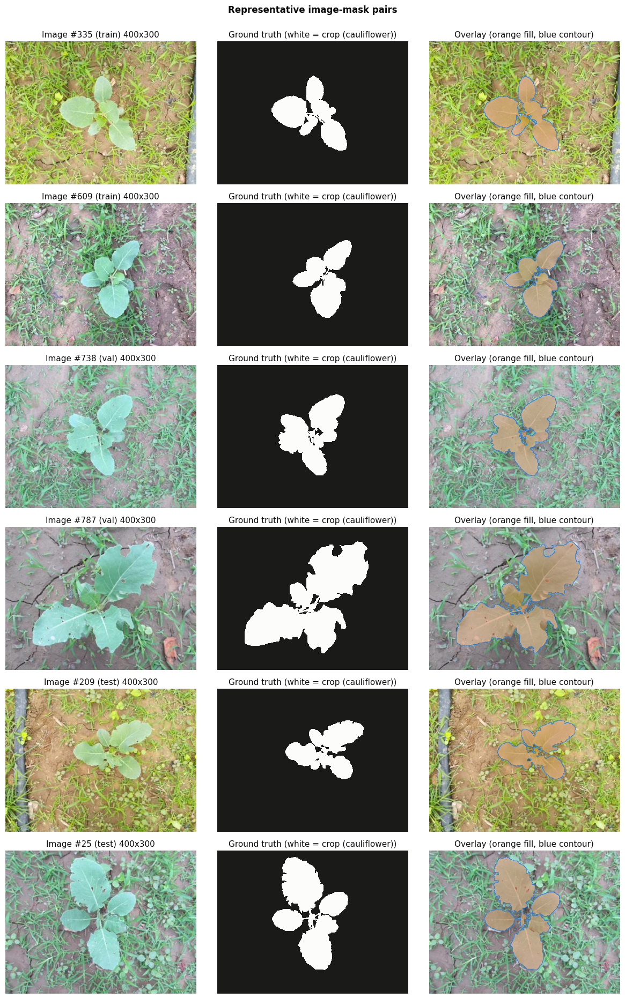

In [17]:
# 4.1 Helper functions for visualisation and morphology + representative pairs ----------
def binary_dilate(mask: np.ndarray, radius: int) -> np.ndarray:
    """Square (chessboard) dilation via max-pooling."""
    m = np.asarray(mask, dtype=bool)
    if radius <= 0:
        return m.copy()
    t = torch.from_numpy(m.astype(np.float32))[None, None]
    return F.max_pool2d(t, 2 * radius + 1, stride=1, padding=radius)[0, 0].numpy() > 0.5


def binary_erode(mask: np.ndarray, radius: int) -> np.ndarray:
    """Square (chessboard) erosion via max-pooling of the complement."""
    m = np.asarray(mask, dtype=bool)
    if radius <= 0:
        return m.copy()
    t = torch.from_numpy(m.astype(np.float32))[None, None]
    return (-F.max_pool2d(-t, 2 * radius + 1, stride=1, padding=radius))[0, 0].numpy() > 0.5


def mask_boundary(mask: np.ndarray, width: int = 1) -> np.ndarray:
    m = np.asarray(mask, dtype=bool)
    return m & ~binary_erode(m, width)


def overlay(rgb: np.ndarray, mask: np.ndarray, color=CROP_RGB, alpha: float = 0.45) -> np.ndarray:
    out = rgb.astype(np.float32).copy()
    m = np.asarray(mask, dtype=bool)
    out[m] = (1 - alpha) * out[m] + alpha * np.asarray(color, np.float32)
    return out.clip(0, 255).astype(np.uint8)


def draw_contour(rgb: np.ndarray, mask: np.ndarray, color=GT_RGB, width: int = 1) -> np.ndarray:
    out = rgb.copy()
    out[mask_boundary(mask, width)] = color
    return out


MASK_CMAP = ListedColormap(["#1a1a19", "#fcfcfb"] if NUM_CLASSES == 2
                           else ["#1a1a19"] + ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                "#e87ba4", "#008300", "#6250d6", "#e34948"][:NUM_CLASSES - 1])

rng_vis = np.random.default_rng(CFG.seed)
groups = [g for g in ("train", "val", "test") if (valid_df["split"] == g).any()] or [None]
show_idx = []
for g in groups:
    pool = valid_df["idx"].to_numpy() if g is None else valid_df.loc[valid_df.split == g, "idx"].to_numpy()
    show_idx += list(rng_vis.choice(pool, size=min(2, len(pool)), replace=False))

fig, axes = plt.subplots(len(show_idx), 3, figsize=(12, 3.1 * len(show_idx)))
axes = np.atleast_2d(axes)
for r, idx in enumerate(show_idx):
    rgb, msk = get_pair(idx)
    split_name = scan_df.loc[idx, "split"]
    axes[r, 0].imshow(rgb)
    axes[r, 0].set_title(f"Image #{idx} ({split_name}) {rgb.shape[1]}x{rgb.shape[0]}")
    axes[r, 1].imshow(msk, cmap=MASK_CMAP, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
    axes[r, 1].set_title(f"Ground truth (white = {CLASS_NAMES[1]})" if NUM_CLASSES == 2 else "Ground truth")
    axes[r, 2].imshow(draw_contour(overlay(rgb, msk > 0), msk > 0))
    axes[r, 2].set_title("Overlay (orange fill, blue contour)")
    for ax in axes[r]:
        ax.axis("off")
fig.suptitle("Representative image-mask pairs", y=1.0, fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_image_mask_pairs", photo=True)
plt.show()

**Reading the figure.** Compare the white mask region with the plants in the photograph. If the annotated region covers the single large broad-leaf plant (the transplanted cauliflower), while the surrounding grasses and small broad-leaf weeds are background, the label semantics stated in Section 1.2 are confirmed. Section 12.3 relies on this interpretation.

### 4.2 Image dimensions

split,test,train,val
resolution,,,
400x300,300,400,88


Image/mask size mismatches excluded: 0


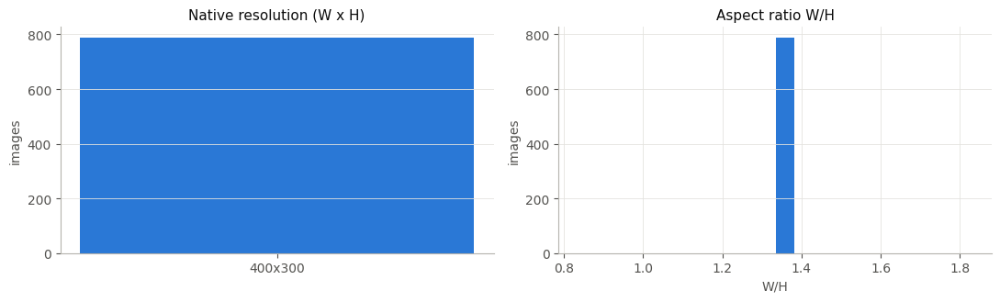

In [18]:
# 4.2 Image dimension analysis ---------------------------------------------------------------
dims = valid_df.assign(resolution=valid_df["img_w"].astype(str) + "x" + valid_df["img_h"].astype(str),
                       aspect=valid_df["img_w"] / valid_df["img_h"])
dim_table = dims.groupby(["resolution", "split"], dropna=False).size().unstack(fill_value=0)
display(dim_table)
print(f"Image/mask size mismatches excluded: {int(scan_df['error'].str.contains('size mismatch').sum())}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
counts = dims["resolution"].value_counts()
axes[0].bar(counts.index, counts.values, color=SERIES[0], width=0.5)
axes[0].set(title="Native resolution (W x H)", ylabel="images")
axes[0].grid(axis="x", visible=False)
axes[1].hist(dims["aspect"], bins=20, color=SERIES[0], rwidth=0.9)
axes[1].set(title="Aspect ratio W/H", xlabel="W/H", ylabel="images")
fig.tight_layout()
save_fig(fig, "eda_image_dimensions")
plt.show()

### 4.3 Class and pixel distributions
Three views of the label distribution: (a) the share of pixels per class in each partition, (b) the per-image distribution of the crop (foreground) fraction, and (c) the **spatial prior**, i.e. the mean training mask, which shows where the crop tends to appear in the frame.

,background (soil + weeds),crop (cauliflower)
split,,
test,0.9079,0.0921
train,0.8997,0.1003
val,0.8957,0.1043


Spatial prior:   0%|          | 0/400 [00:00<?, ?it/s]

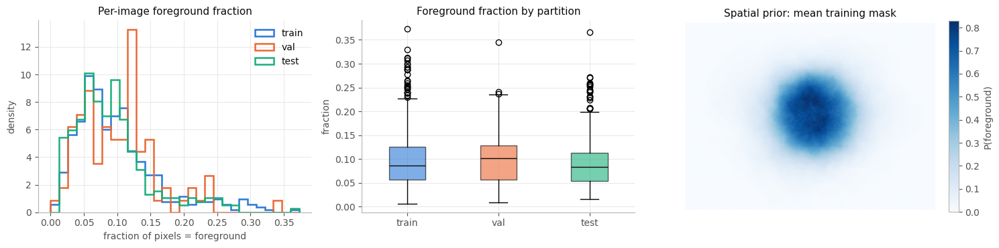

In [19]:
# 4.3 Class and pixel distributions ----------------------------------------------------------
share_rows = []
for g, sub in valid_df.groupby("split", dropna=False):
    cls_px = np.zeros(NUM_CLASSES)
    for i in sub["idx"]:
        for v, c in per_image_counts[i].items():
            k = (value_to_class[v] if CLASS_VALUES is not None else int(v > MASK_BINARISE_THRESHOLD))
            cls_px[k] += c
    share_rows.append({"split": g, **{CLASS_NAMES[k]: cls_px[k] / cls_px.sum() for k in range(NUM_CLASSES)}})
class_share = pd.DataFrame(share_rows).set_index("split")
display(class_share.round(4))

# Spatial prior: mean ground-truth mask of the training split at model resolution
prior_pool = valid_df.loc[valid_df.split == "train", "idx"] if (valid_df.split == "train").any() else valid_df["idx"]
prior = np.zeros((CFG.img_height, CFG.img_width), dtype=np.float64)
for i in tqdm(prior_pool, desc="Spatial prior", leave=False):
    _, m = get_pair(i)
    m_t = TF.resize(torch.from_numpy((m > 0).astype(np.uint8))[None],
                    [CFG.img_height, CFG.img_width], interpolation=InterpolationMode.NEAREST)
    prior += m_t[0].numpy()
prior /= len(prior_pool)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
bins = np.linspace(0, max(0.05, valid_df["fg_fraction"].max()), 30)
for g in [g for g in ("train", "val", "test") if (valid_df.split == g).any()]:
    vals = valid_df.loc[valid_df.split == g, "fg_fraction"]
    axes[0].hist(vals, bins=bins, histtype="step", density=True, color=SPLIT_COLORS[g], linewidth=1.8, label=g)
axes[0].set(title="Per-image foreground fraction", xlabel="fraction of pixels = foreground", ylabel="density")
axes[0].legend()
data_box = [valid_df.loc[valid_df.split == g, "fg_fraction"] for g in ("train", "val", "test") if (valid_df.split == g).any()]
labels_box = [g for g in ("train", "val", "test") if (valid_df.split == g).any()]
if data_box:
    bp = axes[1].boxplot(data_box, widths=0.4, patch_artist=True, medianprops={"color": INK})
    axes[1].set_xticks(range(1, len(labels_box) + 1), labels_box)
    for patch, g in zip(bp["boxes"], labels_box):
        patch.set_facecolor(SPLIT_COLORS[g])
        patch.set_alpha(0.6)
axes[1].set(title="Foreground fraction by partition", ylabel="fraction")
im = axes[2].imshow(prior, cmap="Blues", vmin=0, vmax=max(prior.max(), 1e-6))
axes[2].set_title("Spatial prior: mean training mask")
axes[2].axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.035, label="P(foreground)")
fig.tight_layout()
save_fig(fig, "eda_class_distribution")
plt.show()

### 4.4 Class imbalance
The imbalance ratio $\rho = N_{\text{background}} / N_{\text{foreground}}$, computed on the **training** split, measures how strongly an unweighted pixel loss would favour the majority class. A trivial "all background" predictor would reach a pixel accuracy of $1 - \bar{p}_{fg}$ with a Dice of zero. This is why pixel accuracy alone is a misleading metric here, and why Dice and IoU are the primary metrics.

In [20]:
# 4.4 Class imbalance quantification (training split only) ------------------------------------
train_share = class_share.loc["train"] if "train" in class_share.index else class_share.iloc[0]
fg_share = float(train_share.iloc[1:].sum())
imbalance_ratio = (1 - fg_share) / max(fg_share, 1e-12)
print(f"Training split: foreground pixels = {fg_share:.2%}, background pixels = {1 - fg_share:.2%}")
print(f"Imbalance ratio background : foreground = {imbalance_ratio:.1f} : 1")
print(f"Pixel accuracy of the trivial all-background predictor = {1 - fg_share:.2%} (Dice = 0)")
print(f"Equivalent BCE positive-class weight (not used by default; Dice handles imbalance): {imbalance_ratio:.2f}")

Training split: foreground pixels = 10.03%, background pixels = 89.97%
Imbalance ratio background : foreground = 9.0 : 1
Pixel accuracy of the trivial all-background predictor = 89.97% (Dice = 0)
Equivalent BCE positive-class weight (not used by default; Dice handles imbalance): 8.97


### 4.5 Illumination statistics
The CWF-788 images were acquired on a sunny day (with cast shadows) and on a cloudy day (Li *et al.*, 2019), but the acquisition date is **not** included in the Hub schema. Mean luminance (*brightness*) and its standard deviation (*global contrast*) serve as proxies. Direct sunlight produces cast shadows and therefore higher global contrast. A **bimodal contrast distribution** would be consistent with the two acquisition sessions, but without metadata this remains a hypothesis. Section 13.5 relates these proxies to segmentation quality.

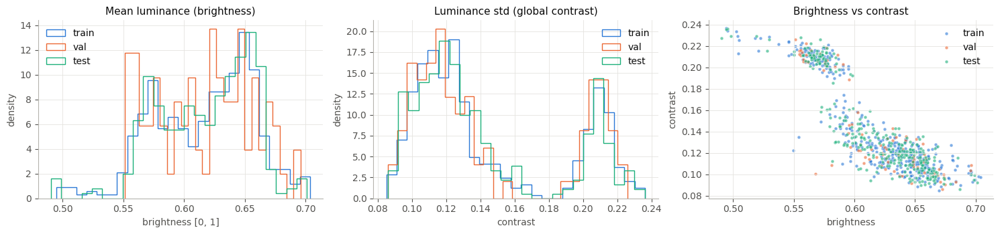

brightness                      contrast                     
            mean    std    min    max     mean    std    min    max
split                                                              
test       0.618  0.039  0.490  0.701    0.141  0.042  0.086  0.236
train      0.617  0.041  0.495  0.704    0.143  0.044  0.085  0.236
val        0.616  0.040  0.551  0.696    0.143  0.045  0.086  0.226

In [21]:
# 4.5 Illumination statistics ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
splits_present = [g for g in ("train", "val", "test") if (valid_df.split == g).any()]
for g in splits_present:
    sub = valid_df[valid_df.split == g]
    axes[0].hist(sub["brightness"], bins=25, histtype="step", density=True, color=SPLIT_COLORS[g], label=g)
    axes[1].hist(sub["contrast"], bins=25, histtype="step", density=True, color=SPLIT_COLORS[g], label=g)
    axes[2].scatter(sub["brightness"], sub["contrast"], s=12, alpha=0.6, color=SPLIT_COLORS[g], label=g,
                    edgecolors="white", linewidths=0.4)
axes[0].set(title="Mean luminance (brightness)", xlabel="brightness [0, 1]", ylabel="density")
axes[1].set(title="Luminance std (global contrast)", xlabel="contrast", ylabel="density")
axes[2].set(title="Brightness vs contrast", xlabel="brightness", ylabel="contrast")
for ax in axes:
    ax.legend()
fig.tight_layout()
save_fig(fig, "eda_illumination")
plt.show()
display(valid_df.groupby("split", dropna=False)[["brightness", "contrast"]].agg(["mean", "std", "min", "max"]).round(3))

### 4.6 EDA observations
The observations below are **generated from the computed statistics**. Qualitative points about image content should be checked against the figures in 4.1.

In [22]:
# 4.6 Data-driven EDA observations ----------------------------------------------------------------
res_counts = dims["resolution"].value_counts()
obs = [
    f"- **{len(valid_df)} valid samples** out of {len(scan_df)} ({n_bad} excluded by the integrity scan).",
    f"- Native resolution: {', '.join(f'{r} ({n} images)' for r, n in res_counts.items())}; "
    f"all images are {'/'.join(sorted(valid_df['img_mode'].unique()))} and masks are "
    f"{'/'.join(sorted(valid_df['mask_mode'].unique()))}.",
    f"- Task inferred from the masks: **{TASK}**, K = {NUM_CLASSES} ({', '.join(CLASS_NAMES)}).",
    f"- Foreground covers **{fg_share:.1%}** of training pixels, an imbalance of **{imbalance_ratio:.1f} : 1**. "
    f"Per-image foreground fraction ranges from {valid_df['fg_fraction'].min():.2%} to "
    f"{valid_df['fg_fraction'].max():.2%} (median {valid_df['fg_fraction'].median():.2%}), so plant size varies widely.",
    f"- Spatial prior: the mean training mask peaks at {prior.max():.2f}, with the centre region "
    f"(middle third) averaging {prior[prior.shape[0]//3:2*prior.shape[0]//3, prior.shape[1]//3:2*prior.shape[1]//3].mean():.3f} "
    f"vs {prior.mean():.3f} over the whole frame, indicating "
    f"{'a strong' if prior[prior.shape[0]//3:2*prior.shape[0]//3, prior.shape[1]//3:2*prior.shape[1]//3].mean() > 2 * prior.mean() else 'a moderate'} "
    "centring of the crop in the frame (photographer bias). Flips and rotations keep this prior plausible.",
    f"- Brightness ranges from {valid_df['brightness'].min():.2f} to {valid_df['brightness'].max():.2f} "
    f"(mean {valid_df['brightness'].mean():.2f}); partitions have mean brightness "
    + ", ".join(f"{g}: {valid_df.loc[valid_df.split == g, 'brightness'].mean():.3f}" for g in splits_present) + ".",
]
display(Markdown("\n".join(obs)))

- **788 valid samples** out of 788 (0 excluded by the integrity scan).
- Native resolution: 400x300 (788 images); all images are RGB and masks are L.
- Task inferred from the masks: **binary**, K = 2 (background (soil + weeds), crop (cauliflower)).
- Foreground covers **10.0%** of training pixels, an imbalance of **9.0 : 1**. Per-image foreground fraction ranges from 0.63% to 37.27% (median 8.67%), so plant size varies widely.
- Spatial prior: the mean training mask peaks at 0.83, with the centre region (middle third) averaging 0.566 vs 0.100 over the whole frame, indicating a strong centring of the crop in the frame (photographer bias). Flips and rotations keep this prior plausible.
- Brightness ranges from 0.49 to 0.70 (mean 0.62); partitions have mean brightness train: 0.617, val: 0.616, test: 0.618.

---
## 5. Data Preprocessing and Partitioning

### 5.1 Design decisions

| Operation | Image | Mask | Rationale |
|---|---|---|---|
| Resize to 288 × 384 | bilinear + antialias | **nearest neighbour** | Interpolating labels would create non-existent classes (e.g. 127 between 0 and 255) |
| Horizontal / vertical flip (p = 0.5 each) | ✔ | ✔ (identical) | Top-down field imagery has no preferred orientation |
| Rotation ± 15° | bilinear, fill 0 | **nearest**, fill 0 = background (identical angle) | Camera roll; nearest keeps labels categorical |
| Brightness / contrast ± 20 % | ✔ | ✘ | Sunny/cloudy acquisition; photometric changes do not move labels |
| Scaling to [0, 1] + standardisation | ✔ (train-split mean/std) | **✘ never** | Masks hold class indices, not intensities |
| Encoding | float32 tensor [3, H, W] | int64 tensor [H, W] of class indices | Required by BCE/CE and Dice implementations |

**Leakage controls.** (1) The authors' official partition is used: no image appears in more than one split. (2) Exact duplicate images across splits are detected by MD5 hash and removed from the evaluation splits. (3) Normalisation statistics are computed on the **training split only**. (4) Augmentation is applied to the training split only. (5) Hyper-parameter decisions (early stopping, LR schedule, threshold calibration) use the validation split. The test split is used **once**, in Section 11.

### 5.2 Partition and leakage audit

In [23]:
# 5.2 Train / validation / test partition + leakage audit ------------------------------------------
rng_split = np.random.default_rng(CFG.seed)
names_present = set(valid_df["split"].dropna())
if {"train", "val", "test"} <= names_present:
    PARTITION_SOURCE = "official partition provided with the dataset"
    split_idx = {s: valid_df.loc[valid_df.split == s, "idx"].to_numpy() for s in ("train", "val", "test")}
elif {"train", "test"} <= names_present:
    PARTITION_SOURCE = "official train/test; validation = seeded hold-out of the official training split"
    tr = rng_split.permutation(valid_df.loc[valid_df.split == "train", "idx"].to_numpy())
    n_val = int(round(len(tr) * CFG.fallback_val_fraction))
    split_idx = {"train": tr[n_val:], "val": tr[:n_val], "test": valid_df.loc[valid_df.split == "test", "idx"].to_numpy()}
else:
    PARTITION_SOURCE = "seeded random partition (no official split found)"
    allidx = rng_split.permutation(valid_df["idx"].to_numpy())
    n_test = int(round(len(allidx) * CFG.fallback_test_fraction))
    n_val = int(round(len(allidx) * CFG.fallback_val_fraction))
    split_idx = {"test": allidx[:n_test], "val": allidx[n_test:n_test + n_val], "train": allidx[n_test + n_val:]}
ignored = names_present - {"train", "val", "test"}
if ignored:
    warnings.warn(f"Rows with unrecognised partition labels {ignored} are not used.")

# Leakage audit 1: disjoint index sets
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    overlap = np.intersect1d(split_idx[a], split_idx[b])
    assert overlap.size == 0, f"Index overlap between {a} and {b}: {overlap[:10]}"

# Leakage audit 2: exact duplicate images across partitions (MD5 of the encoded bytes)
md5 = scan_df.set_index("idx")["md5"]
removed = {}
for earlier, later in (("train", "val"), ("train", "test"), ("val", "test")):
    seen = set(md5.loc[split_idx[earlier]])
    dup = np.array([i for i in split_idx[later] if md5.loc[i] in seen and md5.loc[i] != ""], dtype=np.int64)
    if dup.size:
        split_idx[later] = np.setdiff1d(split_idx[later], dup)
        removed[f"{later} (duplicate of {earlier})"] = dup.tolist()
split_idx = {k: np.sort(v).astype(np.int64) for k, v in split_idx.items()}
dups_within = int(md5[md5 != ""].duplicated().sum())

partition_table = pd.DataFrame({
    "images": {s: len(v) for s, v in split_idx.items()},
    "share": {s: len(v) / sum(map(len, split_idx.values())) for s, v in split_idx.items()},
    "mean fg fraction": {s: scan_df.loc[v, "fg_fraction"].mean() for s, v in split_idx.items()},
}).loc[["train", "val", "test"]]
print(f"Partition source: {PARTITION_SOURCE}")
display(partition_table.round(4))
print("Index sets are pairwise disjoint: OK")
print(f"Duplicate images (identical bytes) anywhere in the dataset: {dups_within}; "
      f"removed from evaluation splits: {sum(map(len, removed.values()))} {removed if removed else ''}")
_ = (RESULTS_DIR / "partition.json").write_text(json.dumps(
    {"source": PARTITION_SOURCE, "removed_duplicates": removed, **{k: v.tolist() for k, v in split_idx.items()}}, indent=1))

Partition source: official partition provided with the dataset


,images,share,mean fg fraction
train,400,0.5076,0.1003
val,88,0.1117,0.1043
test,300,0.3807,0.0921


Index sets are pairwise disjoint: OK
Duplicate images (identical bytes) anywhere in the dataset: 0; removed from evaluation splits: 0 


### 5.3 Normalisation statistics (training split only)
Images are scaled to [0, 1] and standardised per channel, $\tilde{x}_c = (x_c - \mu_c)/\sigma_c$. The network is trained from scratch, so dataset-specific statistics are used instead of ImageNet statistics. They are estimated **exclusively on the training split** so that no information about the evaluation images enters preprocessing.

In [24]:
# 5.3 Channel mean / std from the training split (float64 accumulators) ---------------------
channel_sum = np.zeros(3, dtype=np.float64)
channel_sq = np.zeros(3, dtype=np.float64)
n_pixels = 0
for i in tqdm(split_idx["train"], desc="Normalisation statistics (train)", leave=False):
    rgb, _ = get_pair(i)
    x = rgb.reshape(-1, 3).astype(np.float64) / 255.0
    channel_sum += x.sum(0)
    channel_sq += (x ** 2).sum(0)
    n_pixels += x.shape[0]
NORM_MEAN = tuple(float(v) for v in channel_sum / n_pixels)
NORM_STD = tuple(float(v) for v in np.sqrt(channel_sq / n_pixels - np.asarray(NORM_MEAN) ** 2))
print(f"Training-split mean (R, G, B): {np.round(NORM_MEAN, 4)}")
print(f"Training-split std  (R, G, B): {np.round(NORM_STD, 4)}")
_ = (RESULTS_DIR / "normalisation.json").write_text(json.dumps({"mean": NORM_MEAN, "std": NORM_STD}, indent=2))

Normalisation statistics (train):   0%|          | 0/400 [00:00<?, ?it/s]

Training-split mean (R, G, B): [0.5816 0.6559 0.5115]
Training-split std  (R, G, B): [0.1584 0.168  0.197 ]


### 5.4 Joint image–mask transform
One class implements the whole preprocessing chain. **Geometric** operations draw their random parameters **once** and apply them to the image and the mask; the mask always uses nearest-neighbour interpolation. **Photometric** operations and standardisation are applied to the image only. Random numbers come from PyTorch's generator, which DataLoader workers seed reproducibly.

In [25]:
# 5.4 Joint transform -------------------------------------------------------------------------------
class SegmentationTransform:
    """Resize, augment (training only) and encode an (image, mask) pair.

    Geometric operations share identical random parameters for image and mask; the mask always
    uses nearest-neighbour interpolation and is never normalised. Photometric operations and
    standardisation touch the image only.
    """

    def __init__(self, size, mean, std, train: bool = False, cfg: Config = CFG,
                 brightness_factor: float | None = None,
                 image_interpolation: InterpolationMode = InterpolationMode.BILINEAR):
        self.size = [int(size[0]), int(size[1])]
        self.image_interpolation = image_interpolation  # masks are always nearest-neighbour
        self.mean, self.std = list(mean), list(std)
        self.train, self.cfg = train, cfg
        self.brightness_factor = brightness_factor     # deterministic shift (robustness study)

    @staticmethod
    def _uniform(low: float, high: float) -> float:
        return float(torch.empty(1).uniform_(low, high))

    def __call__(self, image: Image.Image, mask: np.ndarray):
        img = TF.pil_to_tensor(image)                              # uint8 [3, H, W]
        msk = torch.from_numpy(np.ascontiguousarray(mask)).unsqueeze(0)  # uint8 [1, H, W]
        img = TF.resize(img, self.size, interpolation=self.image_interpolation, antialias=True)
        msk = TF.resize(msk, self.size, interpolation=InterpolationMode.NEAREST)
        if self.train:
            c = self.cfg
            if torch.rand(1).item() < c.hflip_p:
                img, msk = TF.horizontal_flip(img), TF.horizontal_flip(msk)
            if torch.rand(1).item() < c.vflip_p:
                img, msk = TF.vertical_flip(img), TF.vertical_flip(msk)
            if c.rotation_degrees > 0:
                angle = self._uniform(-c.rotation_degrees, c.rotation_degrees)
                img = TF.rotate(img, angle, interpolation=self.image_interpolation, fill=[0.0])
                msk = TF.rotate(msk, angle, interpolation=InterpolationMode.NEAREST, fill=[0.0])
            if c.brightness > 0:
                img = TF.adjust_brightness(img, self._uniform(1 - c.brightness, 1 + c.brightness))
            if c.contrast > 0:
                img = TF.adjust_contrast(img, self._uniform(1 - c.contrast, 1 + c.contrast))
        if self.brightness_factor is not None:
            img = TF.adjust_brightness(img, self.brightness_factor)
        img = TF.to_dtype(img, torch.float32, scale=True)         # [0, 1]
        img = TF.normalize(img, mean=self.mean, std=self.std)     # image only
        return img, msk.squeeze(0).long()


IMG_SIZE = (CFG.img_height, CFG.img_width)
train_transform = SegmentationTransform(IMG_SIZE, NORM_MEAN, NORM_STD, train=True)
eval_transform = SegmentationTransform(IMG_SIZE, NORM_MEAN, NORM_STD, train=False)


def denormalise(x: torch.Tensor) -> np.ndarray:
    """[3, H, W] standardised tensor -> uint8 [H, W, 3] for display."""
    mean = torch.tensor(NORM_MEAN).view(3, 1, 1)
    std = torch.tensor(NORM_STD).view(3, 1, 1)
    return (x.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).mul(255).byte().numpy()


print("Transforms ready:", IMG_SIZE)

Transforms ready: (288, 384)


### 5.5 Verification of the augmentation pipeline
Three automatic checks run before any training:
1. **Label integrity.** After augmentation, masks contain only valid class indices and keep dtype `int64`.
2. **Geometric alignment (exact test).** The mask itself is fed in as an RGB image, with photometric jitter disabled and the image path switched to nearest-neighbour interpolation. If image and mask receive *identical* geometric parameters (flip, flip, angle), the transformed "image" must equal the transformed mask **pixel for pixel**. The bilinear interpolation used for real images only softens edges, by about one pixel. The IoU between the bilinear and nearest versions is reported to quantify that effect.
3. **Determinism of the evaluation transform.** Two calls must give identical outputs.

Label integrity: OK | geometric alignment: exact (20/20 draws) | evaluation transform deterministic: OK
Edge softening of bilinear vs nearest image interpolation: IoU min/mean = 0.9673/0.9704


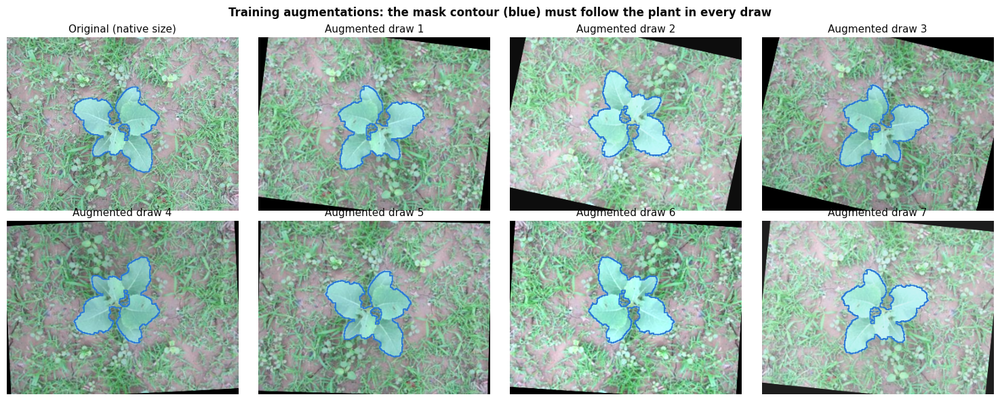

In [26]:
# 5.5 Augmentation verification -----------------------------------------------------------------
probe_idx = int(split_idx["train"][0])
rgb0, msk0 = get_pair(probe_idx)
pil0 = Image.fromarray(rgb0)

# Check 1: label integrity over repeated random draws
for k in range(20):
    torch.manual_seed(k)
    x, y = train_transform(pil0, msk0)
    assert x.shape == (3, *IMG_SIZE) and x.dtype == torch.float32
    assert y.shape == IMG_SIZE and y.dtype == torch.int64
    assert set(torch.unique(y).tolist()) <= set(range(NUM_CLASSES)), "invalid label after augmentation"

# Check 2: exact geometric alignment (mask used as image, no photometric jitter, nearest for both paths)
geo_cfg = Config(**{**asdict(CFG), "brightness": 0.0, "contrast": 0.0})
geo_exact = SegmentationTransform(IMG_SIZE, (0.0, 0.0, 0.0), (1.0, 1.0, 1.0), train=True, cfg=geo_cfg,
                                  image_interpolation=InterpolationMode.NEAREST)
geo_bilinear = SegmentationTransform(IMG_SIZE, (0.0, 0.0, 0.0), (1.0, 1.0, 1.0), train=True, cfg=geo_cfg)
mask_as_img = Image.fromarray(np.repeat(((msk0 > 0) * 255).astype(np.uint8)[..., None], 3, axis=2))
ious = []
for k in range(20):
    torch.manual_seed(k)
    xi, yi = geo_exact(mask_as_img, msk0)
    assert torch.equal(xi[0] > 0.5, yi > 0), f"image/mask misalignment detected in draw {k}"
    torch.manual_seed(k)
    xb_, yb_ = geo_bilinear(mask_as_img, msk0)
    a, b = xb_[0] > 0.5, yb_ > 0
    ious.append(float((a & b).sum() / max((a | b).sum(), 1)))

# Check 3: deterministic evaluation transform
xa, ya = eval_transform(pil0, msk0)
xb, yb = eval_transform(pil0, msk0)
assert torch.equal(xa, xb) and torch.equal(ya, yb)
print("Label integrity: OK | geometric alignment: exact (20/20 draws) | evaluation transform deterministic: OK")
print(f"Edge softening of bilinear vs nearest image interpolation: IoU min/mean = {min(ious):.4f}/{np.mean(ious):.4f}")

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
axes[0, 0].imshow(draw_contour(rgb0, msk0 > 0, width=2))
axes[0, 0].set_title("Original (native size)")
for k, ax in enumerate(axes.flat[1:]):
    torch.manual_seed(100 + k)
    x, y = train_transform(pil0, msk0)
    ax.imshow(draw_contour(denormalise(x), y.numpy() > 0, width=2))
    ax.set_title(f"Augmented draw {k + 1}")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Training augmentations: the mask contour (blue) must follow the plant in every draw",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "preprocessing_augmentation_check", photo=True)
plt.show()

---
## 6. PyTorch Dataset and DataLoader

### 6.1 Custom `Dataset`
`CWF788SegmentationDataset` wraps the memory-mapped Hugging Face table with **undecoded** image columns (`decode=False`). Each `__getitem__` decodes exactly one image–mask pair, maps the raw mask to class indices and applies the transform. Each sample returns its dataset row index, so predictions can be traced back to images in the error analysis. For evaluation, the dataset can also return the **native-resolution mask**, which lets metrics be computed without ever resampling the ground truth (Section 11).

In [28]:
# 6.1 Dataset class --------------------------------------------------------------------------------
class CWF788SegmentationDataset(Dataset):
    def __init__(self, hf_dataset, indices, image_col: str, mask_col: str, transform,
                 return_native_mask: bool = False):
        self.hf = hf_dataset.select_columns([image_col, mask_col])   # undecoded bytes, memory-mapped
        self.indices = np.asarray(indices, dtype=np.int64)
        self.image_col, self.mask_col = image_col, mask_col
        self.transform = transform
        self.return_native_mask = return_native_mask

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, i: int):
        idx = int(self.indices[i])
        row = self.hf[idx]
        image = _decode_from_storage(row[self.image_col]).convert("RGB")
        mask = encode_mask(mask_to_array(_decode_from_storage(row[self.mask_col])))
        x, y = self.transform(image, mask)
        if self.return_native_mask:
            return x, y, torch.from_numpy(mask), idx
        return x, y, idx


def collate_with_native(batch):
    """Stack resized tensors; keep native masks (possibly of different sizes) as a list."""
    xs, ys, natives, idxs = zip(*batch)
    return torch.stack(xs), torch.stack(ys), list(natives), torch.tensor(idxs, dtype=torch.long)

### 6.2 Datasets and loaders
- `train_loader`: shuffled with a seeded generator, `drop_last=True` (avoids a final batch of size 1, which would break BatchNorm statistics).
- `val_loader`: model-resolution masks, used for monitoring during training.
- `val_eval_loader`, `test_loader`: also return native masks, for final evaluation and threshold calibration.
- Worker processes are re-created every epoch (`persistent_workers=False`) so their seeds derive from the per-epoch generator, which keeps resumed runs reproducible.

In [29]:
# 6.2 Datasets and DataLoaders ------------------------------------------------------------------------
train_dataset = CWF788SegmentationDataset(ds_raw, split_idx["train"], IMAGE_COL, MASK_COL, train_transform)
val_dataset = CWF788SegmentationDataset(ds_raw, split_idx["val"], IMAGE_COL, MASK_COL, eval_transform)
val_eval_dataset = CWF788SegmentationDataset(ds_raw, split_idx["val"], IMAGE_COL, MASK_COL, eval_transform,
                                             return_native_mask=True)
test_dataset = CWF788SegmentationDataset(ds_raw, split_idx["test"], IMAGE_COL, MASK_COL, eval_transform,
                                         return_native_mask=True)

LOADER_KW = dict(num_workers=CFG.num_workers, pin_memory=USE_CUDA, worker_init_fn=seed_worker,
                 persistent_workers=False)
train_generator = torch.Generator().manual_seed(CFG.seed)
train_loader = DataLoader(train_dataset, batch_size=CFG.batch_size, shuffle=True, drop_last=True,
                          generator=train_generator, **LOADER_KW)
val_loader = DataLoader(val_dataset, batch_size=CFG.batch_size, shuffle=False, **LOADER_KW)
val_eval_loader = DataLoader(val_eval_dataset, batch_size=CFG.batch_size, shuffle=False,
                             collate_fn=collate_with_native, **LOADER_KW)
test_loader = DataLoader(test_dataset, batch_size=CFG.batch_size, shuffle=False,
                         collate_fn=collate_with_native, **LOADER_KW)

display(pd.DataFrame({
    "images": [len(train_dataset), len(val_dataset), len(test_dataset)],
    "batches": [len(train_loader), len(val_loader), len(test_loader)],
    "batch size": [CFG.batch_size] * 3,
    "augmentation": ["yes", "no", "no"],
}, index=["train", "val", "test"]))
print(f"num_workers = {CFG.num_workers} (platform: {platform.system()}), pin_memory = {USE_CUDA}")

,images,batches,batch size,augmentation
train,400,50,8,yes
val,88,11,8,no
test,300,38,8,no


num_workers = 4 (platform: Linux), pin_memory = True


### 6.3 Tensor shape and type verification

In [30]:
# 6.3 Verify shapes, dtypes and value ranges ------------------------------------------------------------
# Partially consumed multi-worker iterators are deleted and collected explicitly, so their worker
# processes are shut down here and not later inside forked processes.
_iterator = iter(train_loader)
xb, yb, ib = next(_iterator)
del _iterator
assert xb.shape == (CFG.batch_size, 3, *IMG_SIZE), xb.shape
assert xb.dtype == torch.float32 and yb.dtype == torch.int64
assert yb.shape == (CFG.batch_size, *IMG_SIZE)
assert set(torch.unique(yb).tolist()) <= set(range(NUM_CLASSES))
_iterator = iter(test_loader)
xt, yt, nt, it_idx = next(_iterator)
del _iterator
gc.collect()
assert all(n.shape == (scan_df.loc[int(i), "img_h"], scan_df.loc[int(i), "img_w"]) for n, i in zip(nt, it_idx))

print(f"Train images : {tuple(xb.shape)} {xb.dtype} | range [{xb.min():.2f}, {xb.max():.2f}] | "
      f"per-channel mean {xb.mean(dim=(0, 2, 3)).numpy().round(3)} std {xb.std(dim=(0, 2, 3)).numpy().round(3)}")
print(f"Train masks  : {tuple(yb.shape)} {yb.dtype} | classes present {torch.unique(yb).tolist()} | "
      f"foreground fraction {(yb > 0).float().mean():.3f}")
print(f"Test batch   : images {tuple(xt.shape)}, native masks {[tuple(n.shape) for n in nt[:2]]} ...")
print("All tensor checks passed.")

Train images : (8, 3, 288, 384) torch.float32 | range [-3.90, 2.64] | per-channel mean [-0.12  -0.384 -0.52 ] std [1.295 1.33  1.067]
Train masks  : (8, 288, 384) torch.int64 | classes present [0, 1] | foreground fraction 0.089
Test batch   : images (8, 3, 288, 384), native masks [(300, 400), (300, 400)] ...
All tensor checks passed.


### 6.4 Sample training batch

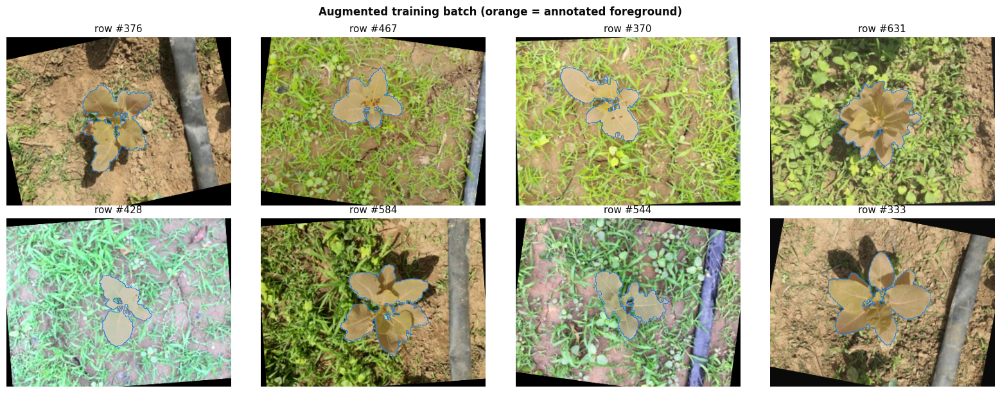

In [31]:
# 6.4 Display a training batch (augmented) ---------------------------------------------------------------
n_show = min(8, xb.shape[0])
cols = 4
rows = math.ceil(n_show / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.1 * rows))
for k, ax in enumerate(np.atleast_1d(axes).flat):
    ax.axis("off")
    if k < n_show:
        ax.imshow(draw_contour(overlay(denormalise(xb[k]), yb[k].numpy() > 0, alpha=0.35), yb[k].numpy() > 0))
        ax.set_title(f"row #{int(ib[k])}")
fig.suptitle("Augmented training batch (orange = annotated foreground)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "dataloader_sample_batch", photo=True)
plt.show()

---
## 7. U-Net Architecture

### 7.1 Architectural components
U-Net (Ronneberger *et al.*, 2015) is a fully convolutional encoder–decoder with a symmetric "U" shape:

| Component | Implementation | Role |
|---|---|---|
| **Double convolution block** | (Conv 3×3 → BatchNorm → ReLU) × 2 | Basic feature extractor at each scale; two stacked 3×3 convolutions give a 5×5 receptive field with fewer parameters and an extra non-linearity |
| **Encoder (contracting path)** | 4 stages of MaxPool 2×2 (stride 2) → double conv; channels double at each stage (64 → 128 → 256 → 512 with `base_filters = 64`) | Captures increasingly abstract, context-rich features (*what*) while lowering spatial resolution |
| **Max pooling** | `nn.MaxPool2d(2)` | Halves the resolution, adds local translation invariance and enlarges the receptive field |
| **Bottleneck** | Deepest double conv (1024 channels) at 1/16 resolution | Widest context; links encoder and decoder |
| **Decoder (expanding path)** | 4 stages of transposed conv 2×2 (stride 2) → concatenation with the skip → double conv; channels halve at each stage | Recovers spatial resolution (*where*) |
| **Transposed convolution** | `nn.ConvTranspose2d(c, c/2, 2, stride=2)` | *Learned* 2× up-sampling (as opposed to fixed interpolation) |
| **Skip connections** | Channel-wise concatenation of the encoder feature map at the same scale | Re-inject high-resolution detail lost by pooling; essential for thin leaf margins and boundaries |
| **Final segmentation layer** | 1×1 convolution to `OUT_CHANNELS` logits | Per-pixel linear classifier. One logit + sigmoid for binary tasks, *K* logits + softmax for multi-class |

**Deliberate, documented deviations from the 2015 paper** (all standard in modern U-Net implementations):
1. *Same padding* (`padding=1`) instead of unpadded convolutions. The output then has the same size as the input, so no border cropping of the skip connections or the output is needed.
2. *Batch Normalisation* after each convolution (Ioffe & Szegedy, 2015), which stabilises and speeds up training from scratch (it can be disabled with `use_batchnorm=False`).
3. No dropout at the end of the contracting path; regularisation relies on data augmentation, weight decay and early stopping.

The weights are initialised with He (Kaiming) normal initialisation, as recommended for ReLU networks (He *et al.*, 2015) and used in the original paper ($\sigma=\sqrt{2/N}$). If the input size is not a multiple of $2^{\text{depth}}$, the forward pass reflect-pads the input and crops the output back, so the model accepts any resolution.

In [33]:
# 7.2 U-Net implementation --------------------------------------------------------------------------
class DoubleConv(nn.Module):
    """(Conv3x3 -> [BN] -> ReLU) x 2 with same padding."""

    def __init__(self, in_ch: int, out_ch: int, use_bn: bool = True):
        super().__init__()
        layers = []
        for c_in, c_out in ((in_ch, out_ch), (out_ch, out_ch)):
            layers.append(nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=not use_bn))
            if use_bn:
                layers.append(nn.BatchNorm2d(c_out))
            layers.append(nn.ReLU(inplace=True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class EncoderBlock(nn.Module):
    """Max-pool 2x2 (stride 2) followed by a double convolution."""

    def __init__(self, in_ch: int, out_ch: int, use_bn: bool = True):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch, use_bn)

    def forward(self, x):
        return self.conv(self.pool(x))


class DecoderBlock(nn.Module):
    """Transposed-conv 2x up-sampling, concatenation with the skip feature map, double convolution."""

    def __init__(self, in_ch: int, out_ch: int, use_bn: bool = True):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = DoubleConv(out_ch * 2, out_ch, use_bn)

    def forward(self, x, skip):
        x = self.up(x)
        dh, dw = skip.shape[-2] - x.shape[-2], skip.shape[-1] - x.shape[-1]
        if dh or dw:  # only needed for odd intermediate sizes
            x = F.pad(x, [dw // 2, dw - dw // 2, dh // 2, dh - dh // 2])
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels: int = 3, out_channels: int = 1, base_filters: int = 64,
                 depth: int = 4, use_bn: bool = True):
        super().__init__()
        widths = [base_filters * 2 ** i for i in range(depth + 1)]   # e.g. 64,128,256,512,1024
        self.depth = depth
        self.stem = DoubleConv(in_channels, widths[0], use_bn)
        self.encoder = nn.ModuleList([EncoderBlock(widths[i], widths[i + 1], use_bn) for i in range(depth - 1)])
        self.bottleneck = EncoderBlock(widths[depth - 1], widths[depth], use_bn)
        self.decoder = nn.ModuleList([DecoderBlock(widths[i + 1], widths[i], use_bn)
                                      for i in reversed(range(depth))])
        self.head = nn.Conv2d(widths[0], out_channels, kernel_size=1)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        h, w = x.shape[-2:]
        m = 2 ** self.depth
        pad_h, pad_w = (-h) % m, (-w) % m
        if pad_h or pad_w:
            x = F.pad(x, [0, pad_w, 0, pad_h], mode="reflect")
        skips = [self.stem(x)]
        for block in self.encoder:
            skips.append(block(skips[-1]))
        x = self.bottleneck(skips[-1])
        for block in self.decoder:
            x = block(x, skips.pop())
        return self.head(x)[..., :h, :w]


def build_model() -> UNet:
    return UNet(in_channels=3, out_channels=OUT_CHANNELS, base_filters=CFG.base_filters,
                depth=CFG.unet_depth, use_bn=CFG.use_batchnorm).to(DEVICE)

### 7.3 Model summary, parameter count and computational cost
The summary lists the output shape and parameter count of each architectural block. FLOPs are measured with PyTorch's `FlopCounterMode` for a single input at the training resolution; one multiply–accumulate counts as 2 FLOPs.

In [34]:
# 7.3 Model summary ------------------------------------------------------------------------------------
set_seed(CFG.seed)
model = build_model()


def model_summary(net: nn.Module, input_shape) -> pd.DataFrame:
    rows, hooks = [], []
    blocks = [("stem", net.stem)] + [(f"encoder[{i}]", b) for i, b in enumerate(net.encoder)] \
        + [("bottleneck", net.bottleneck)] + [(f"decoder[{i}]", b) for i, b in enumerate(net.decoder)] \
        + [("head (1x1 conv)", net.head)]
    for name, module in blocks:
        def hook(mod, inp, out, name=name):
            rows.append({"block": name, "type": mod.__class__.__name__, "output shape": tuple(out.shape),
                         "parameters": sum(p.numel() for p in mod.parameters())})
        hooks.append(module.register_forward_hook(hook))
    net.eval()
    with torch.no_grad():
        net(torch.zeros(1, *input_shape, device=DEVICE))
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)


summary_df = model_summary(model, (3, *IMG_SIZE))
display(summary_df)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
with FlopCounterMode(display=False) as flop_counter:
    with torch.no_grad():
        model(torch.zeros(1, 3, *IMG_SIZE, device=DEVICE))
gflops = flop_counter.get_total_flops() / 1e9
model_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / 1024 ** 2
print(f"Input {IMG_SIZE} -> output channels {OUT_CHANNELS} ({TASK})")
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Parameter memory     : {model_mb:.1f} MiB (float32)")
print(f"Forward cost         : {gflops:.1f} GFLOPs per image at {IMG_SIZE[0]}x{IMG_SIZE[1]}")

,block,type,output shape,parameters
0,stem,DoubleConv,"(1, 64, 288, 384)",38848
1,encoder[0],EncoderBlock,"(1, 128, 144, 192)",221696
2,encoder[1],EncoderBlock,"(1, 256, 72, 96)",885760
3,encoder[2],EncoderBlock,"(1, 512, 36, 48)",3540992
4,bottleneck,EncoderBlock,"(1, 1024, 18, 24)",14159872
5,decoder[0],DecoderBlock,"(1, 512, 36, 48)",9177600
6,decoder[1],DecoderBlock,"(1, 256, 72, 96)",2295040
7,decoder[2],DecoderBlock,"(1, 128, 144, 192)",574080
8,decoder[3],DecoderBlock,"(1, 64, 288, 384)",143680
9,head (1x1 conv),Conv2d,"(1, 1, 288, 384)",65


Input (288, 384) -> output channels 1 (binary)
Total parameters     : 31,037,633
Trainable parameters : 31,037,633
Parameter memory     : 118.4 MiB (float32)
Forward cost         : 162.6 GFLOPs per image at 288x384


### 7.4 Output dimension verification
The output must have the same spatial size as the input and exactly `OUT_CHANNELS` channels. Both the training resolution and the native resolution (300 × 400, not divisible by 16) are tested.

In [35]:
# 7.4 Output dimension checks ------------------------------------------------------------------------------
with torch.no_grad():
    for shape in [(2, 3, *IMG_SIZE), (1, 3, 300, 400), (1, 3, 257, 389)]:
        out = model(torch.randn(*shape, device=DEVICE))
        assert out.shape == (shape[0], OUT_CHANNELS, shape[2], shape[3]), (shape, out.shape)
        print(f"input {shape} -> output {tuple(out.shape)}  OK")

input (2, 3, 288, 384) -> output (2, 1, 288, 384)  OK
input (1, 3, 300, 400) -> output (1, 1, 300, 400)  OK
input (1, 3, 257, 389) -> output (1, 1, 257, 389)  OK


---
## 8. Loss Functions and Evaluation Metrics

### 8.1 Loss functions
Let $z_i$ be the logit of pixel $i$, $p_i=\sigma(z_i)$ its predicted foreground probability and $g_i\in\{0,1\}$ its label, over $N$ pixels of a batch.

**Binary cross-entropy with logits.** It is numerically stable because the sigmoid is fused into the log-likelihood:
$$\mathcal{L}_{\text{BCE}} = -\frac{1}{N}\sum_{i=1}^{N}\big[g_i\log\sigma(z_i) + (1-g_i)\log(1-\sigma(z_i))\big]$$

**Soft Dice loss** (Milletari *et al.*, 2016). It is a differentiable relaxation of the Dice coefficient computed from probabilities. It measures region overlap and is therefore insensitive to the large number of easy background pixels:
$$\mathcal{L}_{\text{Dice}} = 1 - \frac{2\sum_i p_i g_i + \varepsilon}{\sum_i p_i + \sum_i g_i + \varepsilon}, \qquad \varepsilon = 1$$
The sums run over the whole batch (a "batch Dice"), which is more stable than averaging per-image Dice when some images contain small objects.

**Combined loss** used for training:
$$\mathcal{L} = \lambda_{\text{BCE}}\,\mathcal{L}_{\text{BCE}} + \lambda_{\text{Dice}}\,\mathcal{L}_{\text{Dice}}, \qquad \lambda_{\text{BCE}} = \lambda_{\text{Dice}} = 0.5$$
BCE provides dense, well-conditioned per-pixel gradients, especially early in training. Dice directly optimises the evaluation criterion and counteracts class imbalance.

**Multi-class case** ($K>2$, handled automatically): cross-entropy on softmax probabilities, plus the soft Dice averaged over the $K$ one-hot channels.

### 8.2 Evaluation metrics
Predictions are binarised with $\hat{y}_i = \mathbb{1}[p_i > \tau]$ ($\tau = 0.5$ unless stated otherwise), or with $\arg\max$ for multi-class tasks. With TP, FP, FN, TN counted for the **foreground class**:

| Metric | Definition | Interpretation |
|---|---|---|
| Dice coefficient | $\frac{2TP}{2TP+FP+FN}$ | Region overlap; primary metric |
| IoU (Jaccard) | $\frac{TP}{TP+FP+FN}$ | Stricter overlap; $IoU = \frac{Dice}{2-Dice}$ |
| Pixel accuracy | $\frac{TP+TN}{TP+TN+FP+FN}$ | Inflated by the background majority (see 4.4) |
| Precision | $\frac{TP}{TP+FP}$ | Purity: share of predicted crop that is crop (low → weeds mistaken for crop) |
| Recall | $\frac{TP}{TP+FN}$ | Completeness: share of the crop recovered (low → crop missed, at risk of treatment) |
| F1-score | $\frac{2PR}{P+R}$ | Harmonic mean of P and R. **For pixel-level binary segmentation it is algebraically identical to Dice**; both are reported, as the project brief requires |
| mean IoU | IoU averaged over all classes, background included | Common in multi-class benchmarks |

**Aggregation.** *Dataset-level* (micro) metrics accumulate TP/FP/FN/TN over all test pixels. *Per-image* metrics are computed for each image and then averaged (mean ± std), which weights every image equally and exposes variability. In the multi-class case, foreground metrics are macro-averaged over the non-background classes.

In [37]:
# 8.3 Loss functions ------------------------------------------------------------------------------------------
class SoftDiceLoss(nn.Module):
    def __init__(self, task: str, num_classes: int, smooth: float = 1.0):
        super().__init__()
        self.task, self.num_classes, self.smooth = task, num_classes, smooth

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        logits = logits.float()
        if self.task == "binary":
            probs = torch.sigmoid(logits[:, 0])
            tgt = target.float()
            inter = (probs * tgt).sum()
            denom = probs.sum() + tgt.sum()
            return 1.0 - (2.0 * inter + self.smooth) / (denom + self.smooth)
        probs = torch.softmax(logits, dim=1)
        onehot = F.one_hot(target, self.num_classes).permute(0, 3, 1, 2).float()
        dims = (0, 2, 3)
        inter = (probs * onehot).sum(dims)
        denom = probs.sum(dims) + onehot.sum(dims)
        return 1.0 - ((2.0 * inter + self.smooth) / (denom + self.smooth)).mean()


class SegmentationLoss(nn.Module):
    """lambda_pix * (BCE-with-logits | cross-entropy) + lambda_dice * soft Dice."""

    def __init__(self, task: str, num_classes: int, pixel_weight: float = 0.5, dice_weight: float = 0.5):
        super().__init__()
        self.task = task
        self.pixel_weight, self.dice_weight = pixel_weight, dice_weight
        self.pixel_loss = nn.BCEWithLogitsLoss() if task == "binary" else nn.CrossEntropyLoss()
        self.dice_loss = SoftDiceLoss(task, num_classes)

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        logits = logits.float()  # losses always computed in float32 (AMP-safe)
        if self.task == "binary":
            pixel = self.pixel_loss(logits[:, 0], target.float())
        else:
            pixel = self.pixel_loss(logits, target)
        return self.pixel_weight * pixel + self.dice_weight * self.dice_loss(logits, target)


# 8.3 Metrics -------------------------------------------------------------------------------------------------
@torch.no_grad()
def logits_to_pred(logits: torch.Tensor, threshold: float = 0.5, task: str | None = None) -> torch.Tensor:
    """[B, C, H, W] logits -> [B, H, W] class indices."""
    task = task or TASK
    if task == "binary":
        return (torch.sigmoid(logits[:, 0].float()) > threshold).long()
    return logits.argmax(dim=1)


@torch.no_grad()
def confusion_matrix(pred: torch.Tensor, target: torch.Tensor, num_classes: int) -> torch.Tensor:
    """K x K confusion matrix (rows = ground truth, columns = prediction).
    Computed with boolean reductions, which are deterministic on GPU (unlike torch.bincount)."""
    cm = torch.zeros(num_classes, num_classes, dtype=torch.long, device=pred.device)
    for g in range(num_classes):
        is_g = target == g
        for p in range(num_classes):
            cm[g, p] = (is_g & (pred == p)).sum()
    return cm


def _nanmean(values) -> float:
    v = np.asarray(values, dtype=np.float64)
    v = v[~np.isnan(v)]
    return float(v.mean()) if v.size else float("nan")


def metrics_from_cm(cm, task: str | None = None) -> dict:
    """Region metrics from a confusion matrix (foreground classes = 1..K-1)."""
    task = task or TASK
    cm = np.asarray(cm, dtype=np.float64)
    k = cm.shape[0]
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    total = cm.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        dice = 2 * tp / (2 * tp + fp + fn)
        iou = tp / (tp + fp + fn)
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
        f1 = np.where(precision + recall > 0, 2 * precision * recall / (precision + recall),
                      np.where(np.isnan(precision) | np.isnan(recall), np.nan, 0.0))
    fg = [1] if task == "binary" else list(range(1, k))
    return {
        "dice": _nanmean(dice[fg]), "iou": _nanmean(iou[fg]),
        "precision": _nanmean(precision[fg]), "recall": _nanmean(recall[fg]), "f1": _nanmean(f1[fg]),
        "pixel_accuracy": float(tp.sum() / total) if total else float("nan"),
        "miou": _nanmean(iou),
    }

### 8.4 Unit tests for losses and metrics
The implementations are checked against hand-computed values before they are used for training or reporting.

In [38]:
# 8.4 Unit tests -----------------------------------------------------------------------------------------------
# Toy binary example: GT = [[1,1,0],[0,1,0]], prediction = [[1,0,0],[1,1,0]]  ->  TP=2, FP=1, FN=1, TN=2
gt = torch.tensor([[[1, 1, 0], [0, 1, 0]]])
pr = torch.tensor([[[1, 0, 0], [1, 1, 0]]])
m = metrics_from_cm(confusion_matrix(pr, gt, 2).numpy(), task="binary")
expected = {"dice": 4 / 6, "iou": 2 / 4, "precision": 2 / 3, "recall": 2 / 3, "f1": 2 / 3, "pixel_accuracy": 4 / 6}
for key, val in expected.items():
    assert abs(m[key] - val) < 1e-9, (key, m[key], val)
assert abs(m["iou"] - m["dice"] / (2 - m["dice"])) < 1e-9          # IoU = Dice / (2 - Dice)

# Perfect and inverted predictions with saturated logits
target = (torch.rand(2, 32, 32) > 0.7).long()
perfect = (target.float() * 2 - 1)[:, None] * 20.0
loss_b = SegmentationLoss("binary", 2)
assert loss_b(perfect, target).item() < 1e-3
assert SoftDiceLoss("binary", 2)(-perfect, target).item() > 0.99
assert metrics_from_cm(confusion_matrix(logits_to_pred(perfect, task="binary"), target, 2).numpy(), "binary")["dice"] == 1.0

# Multi-class path (3 classes): perfect prediction and gradient flow
t3 = torch.randint(0, 3, (2, 16, 16))
logits3 = F.one_hot(t3, 3).permute(0, 3, 1, 2).float() * 20.0
loss_m = SegmentationLoss("multiclass", 3)
assert loss_m(logits3, t3).item() < 1e-3
m3 = metrics_from_cm(confusion_matrix(logits_to_pred(logits3, task="multiclass"), t3, 3).numpy(), "multiclass")
assert m3["dice"] == 1.0 and m3["miou"] == 1.0
z = torch.zeros(1, OUT_CHANNELS, 8, 8, requires_grad=True)
SegmentationLoss(TASK, NUM_CLASSES)(z, torch.randint(0, NUM_CLASSES, (1, 8, 8))).backward()
assert z.grad is not None and torch.isfinite(z.grad).all()
print("All loss and metric unit tests passed:", {k: round(v, 4) for k, v in m.items()})

All loss and metric unit tests passed: {'dice': 0.6667, 'iou': 0.5, 'precision': 0.6667, 'recall': 0.6667, 'f1': 0.6667, 'pixel_accuracy': 0.6667, 'miou': 0.5}


---
## 9. Model Training

### 9.1 Training protocol
| Element | Choice | Justification |
|---|---|---|
| Optimiser | AdamW (lr = 3·10⁻⁴, weight decay = 10⁻⁴) | Adaptive moments plus *decoupled* weight decay (Loshchilov & Hutter, 2019) |
| LR schedule | `ReduceLROnPlateau` on validation Dice (factor 0.5, patience 4, floor 10⁻⁶) | Lowers the step size only when progress stalls |
| Early stopping | Patience 10 epochs on validation Dice (min Δ = 10⁻⁴) | Stops once the model no longer generalises better |
| Model selection | Highest validation Dice → `best.pt` | The test set plays no part in selection |
| Mixed precision | `torch.autocast` + `GradScaler` on CUDA | Higher throughput on tensor-core GPUs and lower memory; losses still computed in float32 |
| Checkpointing | `last.pt` after **every** epoch; `best.pt` on improvement | Model, optimiser, scheduler, scaler and early-stopping states, epoch, best metric, full history, configuration |
| Atomic writes | Write to `*.tmp`, then `os.replace` | An interruption during saving never corrupts the previous checkpoint |
| Resume | If `last.pt` exists and `CFG.resume`, training continues at `epoch + 1` | Never restarts from epoch 1; per-epoch re-seeding keeps the data stream identical |

**Interrupting and resuming.** Interrupt the kernel at any time (■ or *Kernel → Interrupt*). The last completed epoch is already on disk. Re-running the notebook, or just Sections 9.2–9.4, restores every state and continues from the next epoch. If training stopped because `num_epochs` was reached, increasing `CFG.num_epochs` and re-running extends it. If it ended by early stopping, the run is considered complete. To start a fresh run, change `run_name` or set `resume=False`.

### 9.2 Training components

In [40]:
# 9.2 Training components: functions -------------------------------------------------------------------------
class EarlyStopping:
    """Stop when the monitored metric (maximised) fails to improve by min_delta for `patience` epochs."""

    def __init__(self, patience: int, min_delta: float):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.counter, self.should_stop = -math.inf, 0, False

    def step(self, value: float) -> bool:
        if value > self.best + self.min_delta:
            self.best, self.counter = value, 0
            return True
        self.counter += 1
        self.should_stop = self.counter >= self.patience
        return False

    def state_dict(self) -> dict:
        return {"best": float(self.best), "counter": int(self.counter), "should_stop": bool(self.should_stop)}

    def load_state_dict(self, state: dict) -> None:
        self.best, self.counter, self.should_stop = state["best"], state["counter"], state["should_stop"]


def train_one_epoch(model, loader, criterion, optimizer, scaler, epoch: int) -> dict:
    """One optimisation pass over the training set; returns mean loss and region metrics."""
    model.train()
    loss_sum, n_seen = 0.0, 0
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=DEVICE)
    # tqdm receives an explicit iterator: in Jupyter, tqdm.notebook would otherwise call iter(loader) a second
    # time and leave an idle set of worker processes behind.
    pbar = tqdm(iter(loader), total=len(loader), desc=f"Epoch {epoch:03d} [train]", leave=False)
    for images, masks, _ in pbar:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = model(images)
            loss = criterion(logits, masks)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite training loss at epoch {epoch}: {loss.item()}")
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.item() * images.size(0)
        n_seen += images.size(0)
        cm += confusion_matrix(logits_to_pred(logits.detach(), CFG.threshold), masks, NUM_CLASSES)
        pbar.set_postfix(loss=f"{loss_sum / n_seen:.4f}")
    return {"loss": loss_sum / n_seen, **metrics_from_cm(cm.cpu().numpy())}


@torch.inference_mode()
def validate_one_epoch(model, loader, criterion, epoch: int) -> dict:
    """Evaluation pass at training resolution (used for monitoring and model selection)."""
    model.eval()
    loss_sum, n_seen = 0.0, 0
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=DEVICE)
    for images, masks, _ in tqdm(iter(loader), total=len(loader), desc=f"Epoch {epoch:03d} [val]  ", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = model(images)
        loss_sum += criterion(logits, masks).item() * images.size(0)
        n_seen += images.size(0)
        cm += confusion_matrix(logits_to_pred(logits, CFG.threshold), masks, NUM_CLASSES)
    return {"loss": loss_sum / n_seen, **metrics_from_cm(cm.cpu().numpy())}


ARCH_KEYS = ("base_filters", "unet_depth", "use_batchnorm", "img_height", "img_width")


def save_checkpoint(path: Path, model, optimizer, scheduler, scaler, early_stopper, epoch: int,
                    best_metric: float, best_epoch: int, history: dict, stop_reason: str | None) -> None:
    """Atomically save the complete training state (tmp file + os.replace)."""
    state = {
        "format_version": 1,
        "epoch": int(epoch),
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "early_stopping_state": early_stopper.state_dict(),
        "best_metric": float(best_metric),
        "best_epoch": int(best_epoch),
        "history": {k: [float(v) for v in vals] for k, vals in history.items()},
        "stop_reason": stop_reason,
        "config": asdict(CFG),
        "task": TASK,
        "num_classes": int(NUM_CLASSES),
        "out_channels": int(OUT_CHANNELS),
        "class_values": None if CLASS_VALUES is None else [int(v) for v in CLASS_VALUES],
        "norm_mean": list(NORM_MEAN),
        "norm_std": list(NORM_STD),
        "torch_version": str(torch.__version__),
    }
    tmp = path.with_name(path.name + ".tmp")
    torch.save(state, tmp)
    os.replace(tmp, path)


def load_checkpoint(path: Path, model, optimizer=None, scheduler=None, scaler=None, early_stopper=None) -> dict:
    """Load a checkpoint (weights_only=True: tensors and plain Python containers only)."""
    ckpt = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    if scheduler is not None:
        scheduler.load_state_dict(ckpt["scheduler_state"])
    if scaler is not None:
        scaler.load_state_dict(ckpt["scaler_state"])
    if early_stopper is not None:
        early_stopper.load_state_dict(ckpt["early_stopping_state"])
    return ckpt

### 9.3 Initialisation or resumption

In [41]:
# 9.3 Build the training objects and resume from the last checkpoint if available ---------------------------
set_seed(CFG.seed)
model = build_model()
criterion = SegmentationLoss(TASK, NUM_CLASSES, CFG.bce_weight, CFG.dice_weight).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate, weight_decay=CFG.weight_decay)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=CFG.scheduler_factor,
                                                       patience=CFG.scheduler_patience, min_lr=CFG.min_lr)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
early_stopper = EarlyStopping(CFG.early_stopping_patience, CFG.early_stopping_min_delta)

HISTORY_KEYS = ["epoch", "lr", "epoch_time_s", "train_loss", "train_dice", "train_iou", "train_pixel_accuracy",
                "val_loss", "val_dice", "val_iou", "val_precision", "val_recall", "val_pixel_accuracy"]
history = {k: [] for k in HISTORY_KEYS}
start_epoch, best_metric, best_epoch, stop_reason = 1, -math.inf, 0, None

if CFG.resume and LAST_CKPT.exists():
    ckpt = load_checkpoint(LAST_CKPT, model, optimizer, scheduler, scaler, early_stopper)
    mismatched = {k: (ckpt["config"][k], getattr(CFG, k)) for k in ARCH_KEYS if ckpt["config"][k] != getattr(CFG, k)}
    if mismatched or ckpt["out_channels"] != OUT_CHANNELS:
        raise RuntimeError(f"Checkpoint {LAST_CKPT} was produced with a different architecture/input "
                           f"configuration {mismatched}. Use a new `run_name` or set `resume=False`.")
    start_epoch = ckpt["epoch"] + 1
    best_metric, best_epoch = ckpt["best_metric"], ckpt["best_epoch"]
    history = {k: list(ckpt["history"].get(k, [])) for k in HISTORY_KEYS}
    stop_reason = ckpt["stop_reason"]
    print(f"Resumed from {LAST_CKPT.name}: last completed epoch = {ckpt['epoch']}, "
          f"best val Dice = {best_metric:.4f} (epoch {best_epoch}), stop reason = {stop_reason}.")
    del ckpt
else:
    print("No checkpoint found (or resume disabled): training will start at epoch 1.")

print(f"Planned epochs: {start_epoch} -> {CFG.num_epochs} | optimiser AdamW | AMP {AMP_ENABLED} | "
      f"trainable parameters {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

No checkpoint found (or resume disabled): training will start at epoch 1.
Planned epochs: 1 -> 40 | optimiser AdamW | AMP True | trainable parameters 31,037,633


### 9.4 Training loop
Each epoch prints one summary line; the ★ marks a new best validation Dice. Progress bars show batch-level progress. The training history is written to `results/<run>/training_history.csv` after every epoch.

In [42]:
# 9.4 Training loop (resumable) -------------------------------------------------------------------------------
session_start = time.perf_counter()
epochs_this_session = 0
if stop_reason == "early_stopping":
    print("This run already ended by early stopping: nothing to train. Change `run_name` for a new run.")
elif start_epoch > CFG.num_epochs:
    print(f"All {CFG.num_epochs} planned epochs are complete. Increase `CFG.num_epochs` to continue training.")
else:
    try:
        for epoch in range(start_epoch, CFG.num_epochs + 1):
            set_seed(CFG.seed + epoch)                      # identical data stream with or without resume
            train_generator.manual_seed(CFG.seed + epoch)
            t0 = time.perf_counter()
            lr_epoch = optimizer.param_groups[0]["lr"]
            tr = train_one_epoch(model, train_loader, criterion, optimizer, scaler, epoch)
            va = validate_one_epoch(model, val_loader, criterion, epoch)
            scheduler.step(va["dice"])
            epoch_time = time.perf_counter() - t0

            for key, value in (("epoch", epoch), ("lr", lr_epoch), ("epoch_time_s", epoch_time),
                               ("train_loss", tr["loss"]), ("train_dice", tr["dice"]), ("train_iou", tr["iou"]),
                               ("train_pixel_accuracy", tr["pixel_accuracy"]), ("val_loss", va["loss"]),
                               ("val_dice", va["dice"]), ("val_iou", va["iou"]), ("val_precision", va["precision"]),
                               ("val_recall", va["recall"]), ("val_pixel_accuracy", va["pixel_accuracy"])):
                history[key].append(float(value))

            is_best = va["dice"] > best_metric
            if is_best:
                best_metric, best_epoch = va["dice"], epoch
            early_stopper.step(va["dice"])
            stop_reason = ("early_stopping" if early_stopper.should_stop
                           else "max_epochs" if epoch == CFG.num_epochs else None)
            ckpt_args = (model, optimizer, scheduler, scaler, early_stopper, epoch, best_metric, best_epoch,
                         history, stop_reason)
            if is_best:
                save_checkpoint(BEST_CKPT, *ckpt_args)
            save_checkpoint(LAST_CKPT, *ckpt_args)
            pd.DataFrame(history).to_csv(RESULTS_DIR / "training_history.csv", index=False)
            epochs_this_session += 1

            print(f"Epoch {epoch:03d}/{CFG.num_epochs} | train loss {tr['loss']:.4f} Dice {tr['dice']:.4f} | "
                  f"val loss {va['loss']:.4f} Dice {va['dice']:.4f} IoU {va['iou']:.4f} | "
                  f"lr {lr_epoch:.2e} | {epoch_time:.1f}s{'  ★' if is_best else ''}")
            if early_stopper.should_stop:
                print(f"Early stopping: no improvement > {CFG.early_stopping_min_delta} for "
                      f"{CFG.early_stopping_patience} epochs.")
                break
    except KeyboardInterrupt:
        print(f"\nTraining interrupted. Last completed epoch saved in {LAST_CKPT}. "
              "Re-run Sections 9.3-9.4 (or the whole notebook) to resume.")

session_time = time.perf_counter() - session_start
if USE_CUDA:
    torch.cuda.synchronize()

Epoch 001 [train]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 001 [val]  :   0%|          | 0/11 [00:00<?, ?it/s]

Epoch 001/40 | train loss 0.4474 Dice 0.6158 | val loss 0.2724 Dice 0.8936 IoU 0.8077 | lr 3.00e-04 | 21.2s  ★


Epoch 002 [train]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 002 [val]  :   0%|          | 0/11 [00:00<?, ?it/s]

Epoch 002/40 | train loss 0.2539 Dice 0.8937 | val loss 0.2032 Dice 0.9171 IoU 0.8468 | lr 3.00e-04 | 20.3s  ★


... (110 outputs left out)

Epoch 039/40 | train loss 0.0305 Dice 0.9693 | val loss 0.0290 Dice 0.9713 IoU 0.9442 | lr 3.75e-05 | 20.3s


Epoch 040 [train]:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 040 [val]  :   0%|          | 0/11 [00:00<?, ?it/s]

Epoch 040/40 | train loss 0.0309 Dice 0.9689 | val loss 0.0286 Dice 0.9721 IoU 0.9457 | lr 3.75e-05 | 20.4s  ★


### 9.5 Training summary

In [43]:
# 9.5 Training summary --------------------------------------------------------------------------------------------
if not history["epoch"]:
    raise RuntimeError("No training epoch has been completed: run Section 9.4 first.")
total_train_time = float(np.sum(history["epoch_time_s"]))
training_summary = {
    "epochs_completed": int(history["epoch"][-1]),
    "epochs_this_session": epochs_this_session,
    "best_epoch": int(best_epoch),
    "best_val_dice_training_resolution": float(best_metric),
    "stop_reason": stop_reason or "interrupted / in progress",
    "total_training_time_s": total_train_time,
    "mean_epoch_time_s": float(np.mean(history["epoch_time_s"])),
    "session_wall_time_s": float(session_time),
    "device": str(DEVICE),
}
_ = (RESULTS_DIR / "training_summary.json").write_text(json.dumps(training_summary, indent=2))
display(pd.Series(training_summary, name="value").to_frame())
print(f"Cumulative training time: {total_train_time / 60:.1f} min over {len(history['epoch'])} epochs "
      f"({training_summary['mean_epoch_time_s']:.1f} s/epoch).")

,value
epochs_completed,40
epochs_this_session,40
best_epoch,40
best_val_dice_training_resolution,0.972096
stop_reason,max_epochs
total_training_time_s,814.816067
mean_epoch_time_s,20.370402
session_wall_time_s,841.594292
device,cuda


Cumulative training time: 13.6 min over 40 epochs (20.4 s/epoch).


---
## 10. Training Visualisation

### 10.1 Learning curves
Training metrics are measured on *augmented* batches in training mode (BatchNorm with batch statistics), while validation metrics use the deterministic evaluation pipeline. A gap between the two is therefore expected and is not necessarily overfitting. The dashed line marks the selected (best) epoch.

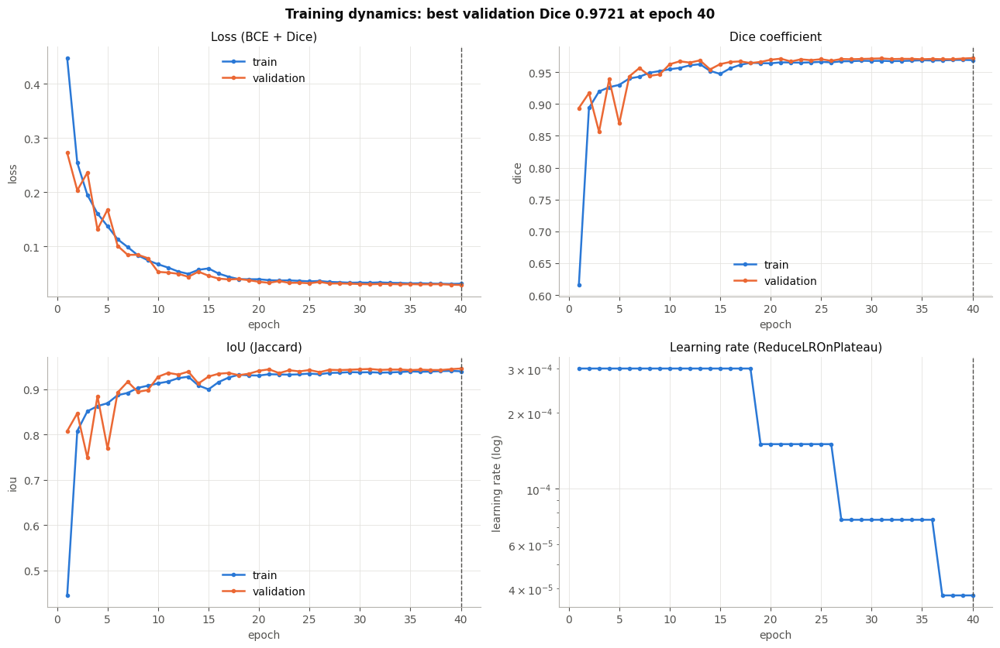

In [44]:
# 10.1 Loss, Dice, IoU and learning-rate curves ---------------------------------------------------------------
hist = pd.DataFrame(history)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
panels = [("loss", "Loss (BCE + Dice)", axes[0, 0]), ("dice", "Dice coefficient", axes[0, 1]),
          ("iou", "IoU (Jaccard)", axes[1, 0])]
for key, title, ax in panels:
    ax.plot(hist["epoch"], hist[f"train_{key}"], color=SPLIT_COLORS["train"], label="train", marker="o", markersize=3)
    ax.plot(hist["epoch"], hist[f"val_{key}"], color=SPLIT_COLORS["val"], label="validation", marker="o", markersize=3)
    ax.axvline(best_epoch, color=INK_2, linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="epoch", ylabel=key)
    ax.legend()
axes[1, 1].plot(hist["epoch"], hist["lr"], color=SERIES[0], marker="o", markersize=3)
axes[1, 1].set_yscale("log")
axes[1, 1].axvline(best_epoch, color=INK_2, linestyle="--", linewidth=1)
axes[1, 1].set(title="Learning rate (ReduceLROnPlateau)", xlabel="epoch", ylabel="learning rate (log)")
for ax in axes.flat:
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
fig.suptitle(f"Training dynamics: best validation Dice {best_metric:.4f} at epoch {best_epoch}", fontweight="bold")
fig.tight_layout()
save_fig(fig, "training_curves")
plt.show()

### 10.2 Convergence analysis
The indicators below are computed from the recorded history: speed of convergence (epochs to reach 95 % of the best validation Dice), stability (dispersion over the last epochs), the number of learning-rate reductions, and the generalisation gap ($\Delta_{\text{loss}} = \mathcal{L}_{val} - \mathcal{L}_{train}$). A gap that keeps growing while validation Dice stalls or falls is the signature of overfitting.

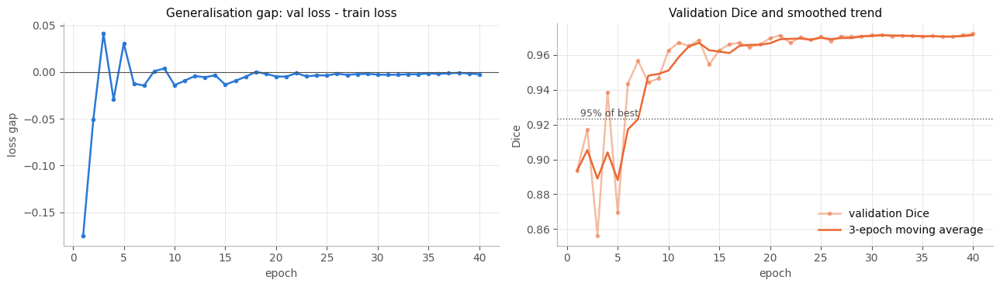

- Best validation Dice **0.9721** at epoch **40** of 40 completed (stop reason: max_epochs).
- 95 % of the best validation Dice was first reached at epoch **4**.
- Learning-rate reductions: **3** (final lr = 3.75e-05).
- Validation Dice over the last 5 epochs: mean 0.9710, std 0.0007 (stable plateau).
- At the best epoch: train loss 0.0309 vs val loss 0.0286 (gap -0.0023); train Dice 0.9689 vs val Dice 0.9721.
- Slope of the loss gap over the last epochs: -0.0001 per epoch (flat or narrowing, no clear overfitting).

In [45]:
# 10.2 Convergence analysis -------------------------------------------------------------------------------------
gap = hist["val_loss"] - hist["train_loss"]
reach95 = hist.loc[hist["val_dice"] >= 0.95 * best_metric, "epoch"]
lr_drops = int((hist["lr"].diff() < 0).sum())
tail = hist["val_dice"].tail(min(5, len(hist)))
best_row = hist.loc[hist["epoch"] == best_epoch].iloc[0]
trend = np.polyfit(hist["epoch"].tail(min(6, len(hist))), gap.tail(min(6, len(hist))), 1)[0] if len(hist) >= 3 else float("nan")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(hist["epoch"], gap, color=SERIES[0], marker="o", markersize=3)
axes[0].axhline(0, color=INK_2, linewidth=0.8)
axes[0].set(title="Generalisation gap: val loss - train loss", xlabel="epoch", ylabel="loss gap")
axes[1].plot(hist["epoch"], hist["val_dice"], color=SPLIT_COLORS["val"], alpha=0.45, marker="o", markersize=3,
             label="validation Dice")
axes[1].plot(hist["epoch"], hist["val_dice"].rolling(3, min_periods=1).mean(), color=SPLIT_COLORS["val"],
             label="3-epoch moving average")
axes[1].axhline(0.95 * best_metric, color=INK_2, linestyle=":", linewidth=1)
axes[1].text(hist["epoch"].iloc[0], 0.95 * best_metric, " 95% of best", va="bottom", color=INK_2, fontsize=9)
axes[1].set(title="Validation Dice and smoothed trend", xlabel="epoch", ylabel="Dice")
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
fig.tight_layout()
save_fig(fig, "training_convergence")
plt.show()

conv = [
    f"- Best validation Dice **{best_metric:.4f}** at epoch **{best_epoch}** of {int(hist['epoch'].iloc[-1])} completed "
    f"(stop reason: {stop_reason or 'not finished'}).",
    f"- 95 % of the best validation Dice was first reached at epoch "
    f"**{int(reach95.iloc[0]) if len(reach95) else 'n/a'}**.",
    f"- Learning-rate reductions: **{lr_drops}** (final lr = {hist['lr'].iloc[-1]:.2e}).",
    f"- Validation Dice over the last {len(tail)} epochs: mean {tail.mean():.4f}, std {tail.std(ddof=0):.4f} "
    f"({'stable' if tail.std(ddof=0) < 0.01 else 'still fluctuating'} plateau).",
    f"- At the best epoch: train loss {best_row['train_loss']:.4f} vs val loss {best_row['val_loss']:.4f} "
    f"(gap {best_row['val_loss'] - best_row['train_loss']:+.4f}); train Dice {best_row['train_dice']:.4f} vs "
    f"val Dice {best_row['val_dice']:.4f}.",
    (f"- Slope of the loss gap over the last epochs: {trend:+.4f} per epoch "
     f"({'widening, a sign of overfitting' if trend > 0.002 else 'flat or narrowing, no clear overfitting'})."
     if np.isfinite(trend) else "- Too few epochs to estimate the trend of the generalisation gap."),
]
display(Markdown("\n".join(conv)))

---
## 11. Test Evaluation

### 11.1 Protocol
- **Model:** the checkpoint with the highest validation Dice (`best.pt`), selected without ever looking at the test split.
- **Native-resolution scoring:** the network predicts at 288 × 384. Its **logits** are bilinearly up-sampled to the native image size (400 × 300) **before** the sigmoid/softmax decision. Metrics are then computed against the **original, never-resampled** ground-truth masks. Resizing the ground truth to the model resolution would alter the annotation and bias the scores.
- **Primary result:** the decision threshold τ = 0.5 is fixed *a priori*. A **secondary** result uses a threshold calibrated on the validation split only (Section 11.4), which is legitimate because the test set plays no part in choosing it.
- **Baseline:** a non-learned Excess-Green + Otsu vegetation detector is evaluated on exactly the same images and masks (Section 11.5). It measures how much of the task colour alone can solve.

In [46]:
# 11.1 Load the selected model --------------------------------------------------------------------------------------
ckpt_path = BEST_CKPT if BEST_CKPT.exists() else LAST_CKPT
if not ckpt_path.exists():
    raise FileNotFoundError(f"No checkpoint in {CKPT_DIR}. Run Section 9 first.")
eval_model = build_model()
eval_ckpt = load_checkpoint(ckpt_path, eval_model)
eval_model.eval()
print(f"Loaded '{ckpt_path.name}': epoch {eval_ckpt['epoch']} | validation Dice at selection "
      f"(training resolution) = {eval_ckpt['best_metric']:.4f}")

Loaded 'best.pt': epoch 40 | validation Dice at selection (training resolution) = 0.9721


In [47]:
# 11.2 Native-resolution inference and evaluation utilities ----------------------------------------------------------
def probs_to_pred(probs: torch.Tensor, threshold: float) -> torch.Tensor:
    return (probs > threshold).long() if TASK == "binary" else probs.argmax(dim=0)


@torch.inference_mode()
def predict_native(model, loader, desc: str = "Inference"):
    """Yield per-image probabilities at native resolution (logits up-sampled before the decision)."""
    model.eval()
    for images, masks, natives, idxs in tqdm(iter(loader), total=len(loader), desc=desc, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = model(images)
        logits = logits.float()
        batch_loss = criterion(logits, masks).item()     # loss at model resolution (same as training)
        for b in range(images.size(0)):
            target = natives[b].long()
            up = F.interpolate(logits[b:b + 1], size=tuple(target.shape), mode="bilinear", align_corners=False)[0]
            probs = torch.sigmoid(up[0]) if TASK == "binary" else torch.softmax(up, dim=0)
            yield {"idx": int(idxs[b]), "probs": probs.cpu(), "target": target,
                   "batch_loss": batch_loss if b == 0 else None, "batch_size": images.size(0)}


def evaluate_split(model, loader, threshold: float = CFG.threshold, desc: str = "Evaluating",
                   store: bool = False):
    """Dataset-level + per-image metrics at native resolution. Optionally keep predictions and targets."""
    rows, kept = [], {"pred": {}, "gt": {}}
    cm_total = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    loss_sum, n_seen = 0.0, 0
    for out in predict_native(model, loader, desc):
        if out["batch_loss"] is not None:
            loss_sum += out["batch_loss"] * out["batch_size"]
            n_seen += out["batch_size"]
        pred = probs_to_pred(out["probs"], threshold)
        cm = confusion_matrix(pred, out["target"], NUM_CLASSES).numpy()
        cm_total += cm
        g_fg, p_fg = out["target"] > 0, pred > 0
        rows.append({"idx": out["idx"], **metrics_from_cm(cm),
                     "tp": int((g_fg & p_fg).sum()), "fp": int((~g_fg & p_fg).sum()),
                     "fn": int((g_fg & ~p_fg).sum()), "tn": int((~g_fg & ~p_fg).sum()),
                     "gt_fraction": float(g_fg.float().mean()), "pred_fraction": float(p_fg.float().mean())})
        if store:
            kept["pred"][out["idx"]] = pred.numpy().astype(np.uint8)
            kept["gt"][out["idx"]] = out["target"].numpy().astype(np.uint8)
    per_image = pd.DataFrame(rows).merge(scan_df[["idx", "brightness", "contrast"]], on="idx", how="left")
    overall = {"loss": loss_sum / max(n_seen, 1), **metrics_from_cm(cm_total)}
    return overall, per_image, cm_total, kept


METRIC_LABELS = [(f"Test loss ({'BCE' if TASK == 'binary' else 'CE'} + Dice)", "loss"),
                 ("Dice coefficient", "dice"), ("IoU (Jaccard)", "iou"), ("Precision", "precision"),
                 ("Recall", "recall"), ("F1-score", "f1"), ("Pixel accuracy", "pixel_accuracy"),
                 ("Mean IoU (all classes)", "miou")]
print("Evaluation utilities ready.")

Evaluation utilities ready.


### 11.3 Test-set results (τ = 0.5)

In [48]:
# 11.3 Evaluate the selected model on the independent test split ------------------------------------------------------
test_overall, test_per_image, test_cm, test_store = evaluate_split(eval_model, test_loader, CFG.threshold,
                                                                   desc="Test set", store=True)
results_table = pd.DataFrame([{
    "Metric": label,
    "Dataset-level (micro)": test_overall[key],
    "Per-image mean": test_per_image[key].mean() if key in test_per_image else np.nan,
    "Per-image std": test_per_image[key].std(ddof=1) if key in test_per_image else np.nan,
} for label, key in METRIC_LABELS])
print(f"U-Net test results: {len(test_per_image)} images, native resolution, threshold {CFG.threshold}")
display(results_table.set_index("Metric").round(4))

cm_df = pd.DataFrame(test_cm, index=[f"GT: {n}" for n in CLASS_NAMES], columns=[f"Pred: {n}" for n in CLASS_NAMES])
print("Confusion matrix (pixels) and row-normalised rates:")
display(cm_df)
display((cm_df.div(cm_df.sum(axis=1), axis=0)).round(4))

results_table.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
_ = (RESULTS_DIR / "test_metrics.md").write_text(df_to_markdown(results_table))
test_per_image.to_csv(RESULTS_DIR / "per_image_test_metrics.csv", index=False)
cm_df.to_csv(RESULTS_DIR / "test_confusion_matrix.csv")

Test set:   0%|          | 0/38 [00:00<?, ?it/s]

U-Net test results: 300 images, native resolution, threshold 0.5


,Dataset-level (micro),Per-image mean,Per-image std
Metric,,,
Test loss (BCE + Dice),0.0290,NaN,NaN
Dice coefficient,0.9763,0.9725,0.0150
IoU (Jaccard),0.9537,0.9470,0.0273
Precision,0.9738,0.9701,0.0191
Recall,0.9788,0.9755,0.0216
F1-score,0.9763,0.9725,0.0150
Pixel accuracy,0.9956,0.9956,0.0025
Mean IoU (all classes),0.9745,0.9710,0.0139


Confusion matrix (pixels) and row-normalised rates:


,Pred: background (soil + weeds),Pred: crop (cauliflower)
GT: background (soil + weeds),32597485,87209
GT: crop (cauliflower),70200,3245106


,Pred: background (soil + weeds),Pred: crop (cauliflower)
GT: background (soil + weeds),0.9973,0.0027
GT: crop (cauliflower),0.0212,0.9788


### 11.4 Validation-based threshold calibration
For the binary task the sigmoid output is a score, and τ = 0.5 is not necessarily the optimal operating point under class imbalance. Dice, precision and recall are swept over τ on the **validation** split. The Dice-maximising τ* is then applied **once** to the test split. The same pass also gives the validation metrics at native resolution, which are used in Section 14 to quantify generalisation.

In [49]:
# 11.4 Threshold sweep on validation + validation metrics at native resolution ------------------------------------------
val_overall, val_per_image, _, _ = evaluate_split(eval_model, val_eval_loader, CFG.threshold, desc="Validation (native)")
TAU_CAL, test_cal_overall, test_cal_per_image, sweep = None, None, None, None
if TASK == "binary":
    THRESHOLDS = np.unique(np.round(np.append(np.arange(0.05, 0.951, 0.05), CFG.threshold), 3))
    counts = np.zeros((len(THRESHOLDS), 3), dtype=np.float64)            # TP, FP, FN per threshold
    for out in predict_native(eval_model, val_eval_loader, desc="Threshold sweep (validation)"):
        p, g = out["probs"], out["target"] == 1
        for j, t in enumerate(THRESHOLDS):
            pr = p > t
            counts[j] += (int((pr & g).sum()), int((pr & ~g).sum()), int((~pr & g).sum()))
    tp, fp, fn = counts.T
    with np.errstate(divide="ignore", invalid="ignore"):
        sweep = pd.DataFrame({"threshold": THRESHOLDS, "dice": 2 * tp / (2 * tp + fp + fn),
                              "iou": tp / (tp + fp + fn), "precision": tp / (tp + fp), "recall": tp / (tp + fn)})
    TAU_CAL = float(sweep.loc[sweep["dice"].idxmax(), "threshold"])
    sweep.to_csv(RESULTS_DIR / "val_threshold_sweep.csv", index=False)
    test_cal_overall, test_cal_per_image, _, _ = evaluate_split(eval_model, test_loader, TAU_CAL,
                                                                desc=f"Test set (tau={TAU_CAL})")
    print(f"Validation Dice at tau={CFG.threshold}: {sweep.loc[np.isclose(sweep.threshold, CFG.threshold), 'dice'].iloc[0]:.4f} | "
          f"best validation Dice {sweep['dice'].max():.4f} at tau* = {TAU_CAL}")
    print(f"Test Dice with tau* = {TAU_CAL}: {test_cal_overall['dice']:.4f} "
          f"(vs {test_overall['dice']:.4f} at tau = {CFG.threshold})")
else:
    print("Multi-class task: arg-max decision, no threshold calibration.")
print(f"Validation metrics at native resolution (tau={CFG.threshold}): "
      + ", ".join(f"{k} {v:.4f}" for k, v in val_overall.items()))

Validation (native):   0%|          | 0/11 [00:00<?, ?it/s]

Threshold sweep (validation):   0%|          | 0/11 [00:00<?, ?it/s]

Test set (tau=0.6):   0%|          | 0/38 [00:00<?, ?it/s]

Validation Dice at tau=0.5: 0.9772 | best validation Dice 0.9773 at tau* = 0.6
Test Dice with tau* = 0.6: 0.9761 (vs 0.9763 at tau = 0.5)
Validation metrics at native resolution (tau=0.5): loss 0.0286, dice 0.9772, iou 0.9554, precision 0.9730, recall 0.9814, f1 0.9772, pixel_accuracy 0.9952, miou 0.9750


### 11.5 Experimentally evaluated baseline: Excess-Green + Otsu
The ExG index $\text{ExG} = 2g - r - b$ on chromatic coordinates ($r = R/(R+G+B)$, etc.; Woebbecke *et al.*, 1995), thresholded per image with Otsu's method (Otsu, 1979), is a classic vegetation/soil separator. Used as a "crop" detector, it labels **all** vegetation, crop and weeds alike, as foreground. Its recall is therefore expected to be high and its precision limited by weed density. The comparison quantifies the value added by learned shape and context features. Both methods are scored on identical native-resolution masks.

In [50]:
# 11.5 ExG + Otsu baseline and final comparison table ----------------------------------------------------------------------
def excess_green(rgb: np.ndarray) -> np.ndarray:
    x = rgb.astype(np.float32)
    s = x.sum(axis=-1) + 1e-6
    return 2 * x[..., 1] / s - x[..., 0] / s - x[..., 2] / s


def otsu_threshold(values: np.ndarray, bins: int = 256) -> float:
    hist, edges = np.histogram(values, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist).astype(np.float64)
    w1 = w0[-1] - w0
    m0 = np.cumsum(hist * centers)
    mu0 = m0 / np.maximum(w0, 1)
    mu1 = (m0[-1] - m0) / np.maximum(w1, 1)
    return float(centers[np.argmax(w0 * w1 * (mu0 - mu1) ** 2)])


def vegetation_mask(rgb: np.ndarray) -> np.ndarray:
    exg = excess_green(rgb)
    return exg > otsu_threshold(exg.ravel())


def row_from(name, overall, per_image):
    return {"Method": name, "Dice": overall["dice"], "IoU": overall["iou"], "Precision": overall["precision"],
            "Recall": overall["recall"], "F1": overall["f1"], "Pixel accuracy": overall["pixel_accuracy"],
            "Per-image Dice (mean)": per_image["dice"].mean(), "Per-image Dice (std)": per_image["dice"].std(ddof=1)}


primary_name = f"U-Net (tau = {CFG.threshold}) [primary]" if TASK == "binary" else "U-Net (arg-max) [primary]"
final_rows = [row_from(primary_name, test_overall, test_per_image)]
baseline_overall = baseline_per_image = None
if TASK == "binary":
    final_rows.append(row_from(f"U-Net (tau* = {TAU_CAL}, calibrated on validation)", test_cal_overall, test_cal_per_image))
    cm_base = np.zeros((2, 2), dtype=np.int64)
    base_rows = []
    for i in tqdm(split_idx["test"], desc="ExG + Otsu baseline", leave=False):
        rgb, _ = get_pair(i)
        veg = torch.from_numpy(vegetation_mask(rgb).astype(np.int64))
        gt_t = torch.from_numpy(test_store["gt"][int(i)].astype(np.int64))
        cm = confusion_matrix(veg, gt_t, 2).numpy()
        cm_base += cm
        base_rows.append({"idx": int(i), **metrics_from_cm(cm, "binary")})
    baseline_overall = metrics_from_cm(cm_base, "binary")
    baseline_per_image = pd.DataFrame(base_rows)
    final_rows.append(row_from("ExG + Otsu (all vegetation = crop), non-learned", baseline_overall, baseline_per_image))

final_table = pd.DataFrame(final_rows)
print("FINAL RESULTS TABLE - independent test split, native resolution, dataset-level metrics")
display(final_table.set_index("Method").round(4))
final_table.to_csv(RESULTS_DIR / "final_results_table.csv", index=False)
_ = (RESULTS_DIR / "final_results_table.md").write_text(
    f"Test split: {len(split_idx['test'])} images, native resolution.\n\n" + df_to_markdown(final_table))

ExG + Otsu baseline:   0%|          | 0/300 [00:00<?, ?it/s]

FINAL RESULTS TABLE - independent test split, native resolution, dataset-level metrics


,Dice,IoU,Precision,Recall,F1,Pixel accuracy,Per-image Dice (mean),Per-image Dice (std)
Method,,,,,,,,
U-Net (tau = 0.5) [primary],0.9763,0.9537,0.9738,0.9788,0.9763,0.9956,0.9725,0.0150
"U-Net (tau* = 0.6, calibrated on validation)",0.9761,0.9534,0.9778,0.9745,0.9761,0.9956,0.9723,0.0153
"ExG + Otsu (all vegetation = crop), non-learned",0.2317,0.1310,0.1414,0.6396,0.2317,0.6093,0.2186,0.1914


---
## 12. Qualitative Results

### 12.1 Best, median and worst test predictions
Test images are ranked by per-image Dice. The best, median and worst examples are shown with four panels: **(1)** the original image, **(2)** the ground-truth mask, **(3)** the predicted mask, **(4)** an overlay with the prediction filled in orange and the ground-truth contour in blue.

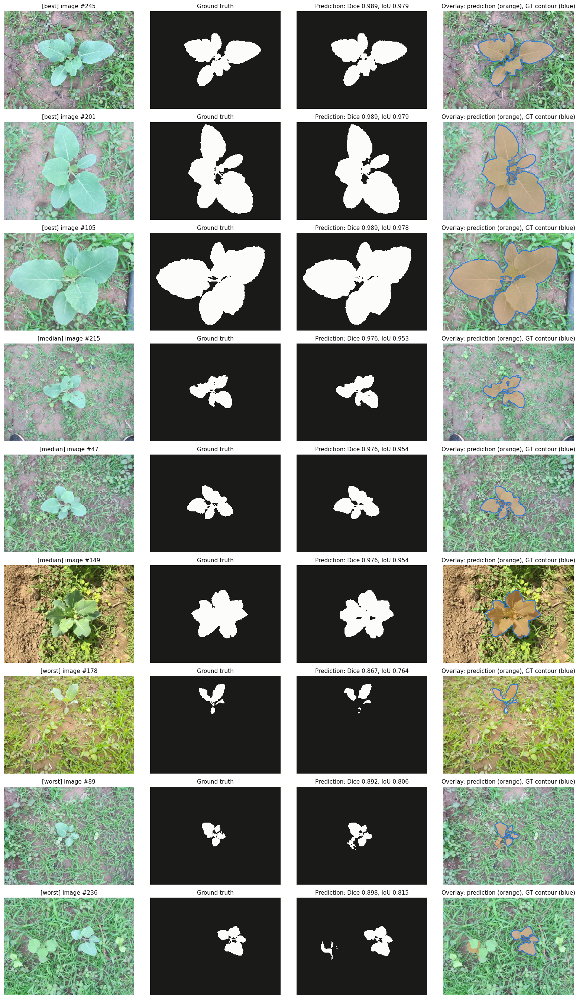

In [51]:
# 12.1 Qualitative examples -------------------------------------------------------------------------------------------------
ranked = test_per_image.sort_values("dice").reset_index(drop=True)
n_q = min(CFG.n_qualitative, len(ranked))
mid = len(ranked) // 2
selection = ([("best", r) for r in ranked.tail(n_q).iloc[::-1].itertuples()]
             + [("median", r) for r in ranked.iloc[max(0, mid - n_q // 2): max(0, mid - n_q // 2) + n_q].itertuples()]
             + [("worst", r) for r in ranked.head(n_q).itertuples()])

fig, axes = plt.subplots(len(selection), 4, figsize=(16, 3.0 * len(selection)))
axes = np.atleast_2d(axes)
for r, (group, rec) in enumerate(selection):
    rgb, _ = get_pair(rec.idx)
    gt = test_store["gt"][rec.idx]
    pred = test_store["pred"][rec.idx]
    axes[r, 0].imshow(rgb)
    axes[r, 0].set_title(f"[{group}] image #{rec.idx}")
    axes[r, 1].imshow(gt, cmap=MASK_CMAP, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
    axes[r, 1].set_title("Ground truth")
    axes[r, 2].imshow(pred, cmap=MASK_CMAP, vmin=0, vmax=NUM_CLASSES - 1, interpolation="nearest")
    axes[r, 2].set_title(f"Prediction: Dice {rec.dice:.3f}, IoU {rec.iou:.3f}")
    axes[r, 3].imshow(draw_contour(overlay(rgb, pred > 0), gt > 0, width=2))
    axes[r, 3].set_title("Overlay: prediction (orange), GT contour (blue)")
    for ax in axes[r]:
        ax.axis("off")
fig.tight_layout()
save_fig(fig, "qualitative_best_median_worst", photo=True)
plt.show()

### 12.2 Analysis of successes and failures
When reading the figure, look for:
- **Successes:** isolated, well-lit crop plants with a clear leaf outline. Errors there should concentrate in thin bands along the leaf margins (see Section 13.2).
- **Typical failure modes:** (i) broad-leaf weeds touching or overlapping the crop and absorbed into the crop mask (false positives); (ii) crop leaves in cast shadow or with specular highlights that are missed (false negatives); (iii) very small or young plants, where a few pixels of error weigh heavily on Dice; (iv) leaves cut by the image border.

The statistics below are computed from the per-image results and tell you which of these modes dominate in this run.

In [52]:
# 12.2 Data-driven qualitative summary ----------------------------------------------------------------------------------------
bands = [(0.9, 1.01, "Dice >= 0.90"), (0.8, 0.9, "0.80 <= Dice < 0.90"), (0.7, 0.8, "0.70 <= Dice < 0.80"),
         (-0.01, 0.7, "Dice < 0.70")]
lines = [f"- {label}: **{int(((test_per_image.dice >= lo) & (test_per_image.dice < hi)).sum())}** images "
         f"({((test_per_image.dice >= lo) & (test_per_image.dice < hi)).mean():.1%})" for lo, hi, label in bands]
k_dec = max(1, len(ranked) // 10)
worst_dec, rest = ranked.head(k_dec), ranked.iloc[k_dec:]
lines += [
    f"- Worst decile ({k_dec} images): mean Dice {worst_dec.dice.mean():.3f}, mean GT foreground fraction "
    f"{worst_dec.gt_fraction.mean():.2%} vs {rest.gt_fraction.mean():.2%} for the other images; mean brightness "
    f"{worst_dec.brightness.mean():.3f} vs {rest.brightness.mean():.3f}.",
    f"- Worst decile error composition: FP pixels {worst_dec.fp.sum():,} vs FN pixels {worst_dec.fn.sum():,} "
    f"({'mainly over-segmentation' if worst_dec.fp.sum() > worst_dec.fn.sum() else 'mainly under-segmentation'}).",
]
display(Markdown("\n".join(lines)))

- Dice >= 0.90: **297** images (99.0%)
- 0.80 <= Dice < 0.90: **3** images (1.0%)
- 0.70 <= Dice < 0.80: **0** images (0.0%)
- Dice < 0.70: **0** images (0.0%)
- Worst decile (30 images): mean Dice 0.937, mean GT foreground fraction 4.95% vs 9.68% for the other images; mean brightness 0.609 vs 0.619.
- Worst decile error composition: FP pixels 10,467 vs FN pixels 10,790 (mainly under-segmentation).

### 12.3 From crop segmentation to weed maps
The ground truth of CWF-788 annotates the crop, so weeds are not labelled directly. In a field, however, vegetation that is **not** crop is weed by definition. A weed map is therefore derived as

$$\widehat{W} = V_{\text{ExG}} \;\cap\; \neg\,\mathrm{dilate}_r\big(\widehat{C}_{\text{U-Net}}\big)$$

where $V_{\text{ExG}}$ is the ExG/Otsu vegetation mask, $\widehat{C}$ the U-Net crop prediction, and $r$ (`weed_map_crop_margin_px`) a small safety margin around the crop, as a precision sprayer would apply.

> **Validity statement.** No weed-level ground truth exists, so $\widehat{W}$ **cannot be scored** for weed precision or recall, and the estimated weed cover is reported as an indicator only. One component *can* be measured: the **crop-protection error**, i.e. the share of true crop pixels that the weed map would wrongly target for treatment.

Weed maps:   0%|          | 0/300 [00:00<?, ?it/s]

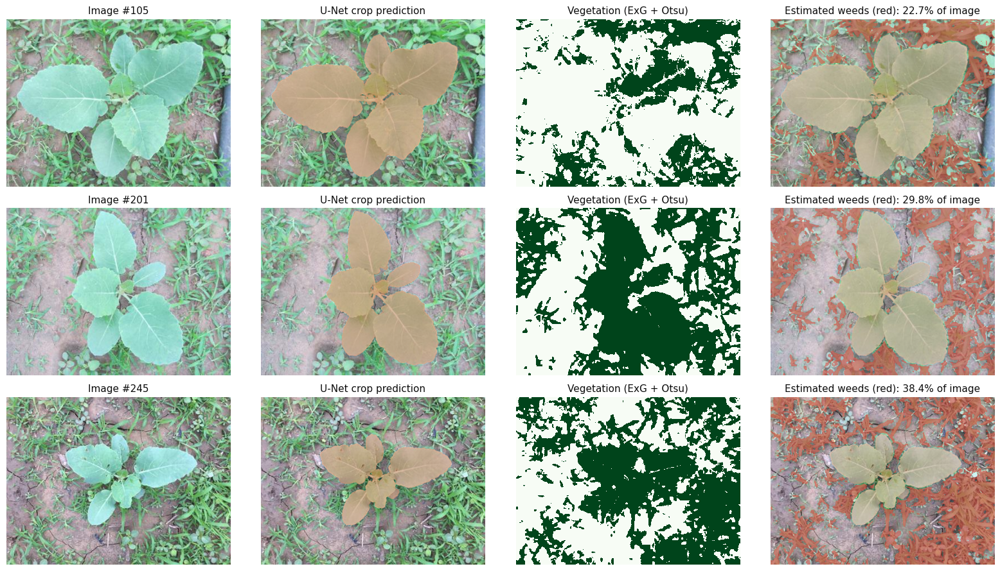

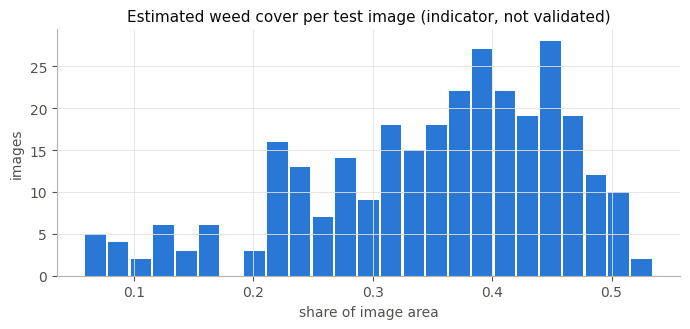

,vegetation_cover,pred_crop_cover,est_weed_cover,crop_targeted_share
mean,0.4164,0.0926,0.3506,0.0018
std,0.1102,0.0570,0.1078,0.0057
min,0.1664,0.0164,0.0584,0.0000
50%,0.4390,0.0842,0.3701,0.0000
max,0.6475,0.3668,0.5346,0.0576


Crop-protection error: on average 0.18% of true crop pixels would be targeted by the derived weed map (margin r = 2 px).


In [53]:
# 12.3 Derived weed maps (binary crop-vs-background task only) -------------------------------------------------------------------
weed_df = None
if TASK == "binary":
    weed_rows, weed_examples = [], {}
    example_ids = [rec.idx for g, rec in selection if g in ("best", "median")][:3]
    for i in tqdm(split_idx["test"], desc="Weed maps", leave=False):
        i = int(i)
        rgb, _ = get_pair(i)
        gt = test_store["gt"][i] > 0
        crop_pred = test_store["pred"][i] > 0
        veg = vegetation_mask(rgb)
        weed = veg & ~binary_dilate(crop_pred, CFG.weed_map_crop_margin_px)
        weed_rows.append({"idx": i, "vegetation_cover": veg.mean(), "pred_crop_cover": crop_pred.mean(),
                          "est_weed_cover": weed.mean(),
                          "crop_targeted_share": (weed & gt).sum() / max(gt.sum(), 1)})
        if i in example_ids:
            weed_examples[i] = (rgb, crop_pred, veg, weed)
    weed_df = pd.DataFrame(weed_rows)
    weed_df.to_csv(RESULTS_DIR / "derived_weed_maps.csv", index=False)

    fig, axes = plt.subplots(len(weed_examples), 4, figsize=(16, 3.0 * len(weed_examples)))
    axes = np.atleast_2d(axes)
    for r, (i, (rgb, crop_pred, veg, weed)) in enumerate(weed_examples.items()):
        axes[r, 0].imshow(rgb)
        axes[r, 0].set_title(f"Image #{i}")
        axes[r, 1].imshow(overlay(rgb, crop_pred))
        axes[r, 1].set_title("U-Net crop prediction")
        axes[r, 2].imshow(veg, cmap="Greens", interpolation="nearest")
        axes[r, 2].set_title("Vegetation (ExG + Otsu)")
        axes[r, 3].imshow(overlay(overlay(rgb, crop_pred, alpha=0.35), weed, color=FP_RGB, alpha=0.6))
        axes[r, 3].set_title(f"Estimated weeds (red): {weed.mean():.1%} of image")
        for ax in axes[r]:
            ax.axis("off")
    fig.tight_layout()
    save_fig(fig, "derived_weed_maps", photo=True)
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.hist(weed_df["est_weed_cover"], bins=25, color=SERIES[0], rwidth=0.9)
    ax.set(title="Estimated weed cover per test image (indicator, not validated)",
           xlabel="share of image area", ylabel="images")
    fig.tight_layout()
    save_fig(fig, "derived_weed_cover_hist")
    plt.show()
    display(weed_df[["vegetation_cover", "pred_crop_cover", "est_weed_cover", "crop_targeted_share"]]
            .describe().loc[["mean", "std", "min", "50%", "max"]].round(4))
    print(f"Crop-protection error: on average {weed_df.crop_targeted_share.mean():.2%} of true crop pixels "
          f"would be targeted by the derived weed map (margin r = {CFG.weed_map_crop_margin_px} px).")
else:
    print("Weed-map derivation is defined for the binary crop-vs-background setting only.")

---
## 13. Error Analysis

### 13.1 False positives and false negatives
Agronomically, a **false positive** (weed or soil labelled as crop) leaves a weed untreated. A **false negative** (crop missed) exposes crop tissue to treatment, which is usually the more costly error for a selective sprayer or mechanical weeder. The error maps use green for TP, red for FP and blue for FN, drawn over a dimmed greyscale image.

Foreground-level error pixels on the test split: FP = 87,209, FN = 70,200 (FP share of all errors = 55.4%)
False-positive rate (background predicted as foreground) = 0.0027
False-negative rate (foreground missed)                 = 0.0212


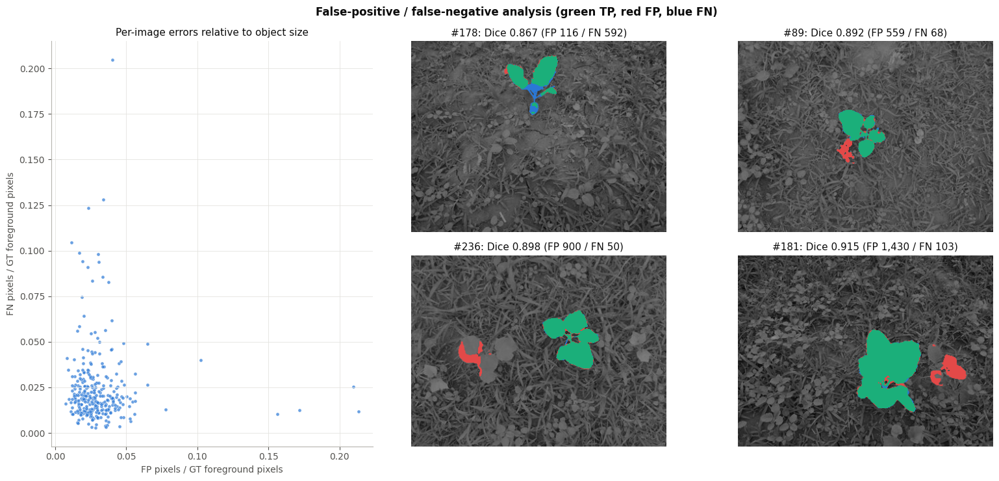

In [54]:
# 13.1 FP / FN analysis ----------------------------------------------------------------------------------------------------------
def error_map(rgb: np.ndarray, gt: np.ndarray, pred: np.ndarray) -> np.ndarray:
    grey = rgb.mean(axis=-1, keepdims=True).repeat(3, axis=-1) * 0.55
    out = grey.copy()
    g, p = gt > 0, pred > 0
    out[g & p] = TP_RGB
    out[~g & p] = FP_RGB
    out[g & ~p] = FN_RGB
    return out.clip(0, 255).astype(np.uint8)


tot = test_per_image[["tp", "fp", "fn", "tn"]].sum()
fp_rate = tot.fp / (tot.fp + tot.tn)
fn_rate = tot.fn / (tot.fn + tot.tp)
print(f"Foreground-level error pixels on the test split: FP = {tot.fp:,}, FN = {tot.fn:,} "
      f"(FP share of all errors = {tot.fp / max(tot.fp + tot.fn, 1):.1%})")
print(f"False-positive rate (background predicted as foreground) = {fp_rate:.4f}")
print(f"False-negative rate (foreground missed)                 = {fn_rate:.4f}")

gt_px = (test_per_image.tp + test_per_image.fn).clip(lower=1)
fig = plt.figure(figsize=(16, 7.5))
ax0 = fig.add_subplot(2, 3, (1, 4))
ax0.scatter(test_per_image.fp / gt_px, test_per_image.fn / gt_px, s=14, color=SERIES[0], alpha=0.7,
            edgecolors="white", linewidths=0.4)
ax0.set(title="Per-image errors relative to object size", xlabel="FP pixels / GT foreground pixels",
        ylabel="FN pixels / GT foreground pixels")
worst4 = ranked.head(min(4, len(ranked)))
for k, rec in enumerate(worst4.itertuples()):
    ax = fig.add_subplot(2, 3, [2, 3, 5, 6][k])
    rgb, _ = get_pair(rec.idx)
    ax.imshow(error_map(rgb, test_store["gt"][rec.idx], test_store["pred"][rec.idx]))
    ax.set_title(f"#{rec.idx}: Dice {rec.dice:.3f} (FP {rec.fp:,} / FN {rec.fn:,})")
    ax.axis("off")
fig.suptitle("False-positive / false-negative analysis (green TP, red FP, blue FN)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "error_fp_fn", photo=True)
plt.show()

### 13.2 Boundary errors
Region metrics weight large objects heavily and are insensitive to the quality of contours. Two boundary-focused analyses are reported: **Boundary IoU** (Cheng *et al.*, 2021), which is the IoU restricted to the inner bands of width *d* along the ground-truth and predicted contours, with *d* = 2 % of the image diagonal as recommended by the authors (≈ 10 px for 400 × 300 images), and the **distance distribution of error pixels** from the ground-truth contour. If most errors lie within a few pixels of the contour, the remaining error is mainly a matter of boundary precision, which is partly bounded by annotation accuracy, rather than of misdetected objects.

Boundary analysis:   0%|          | 0/300 [00:00<?, ?it/s]

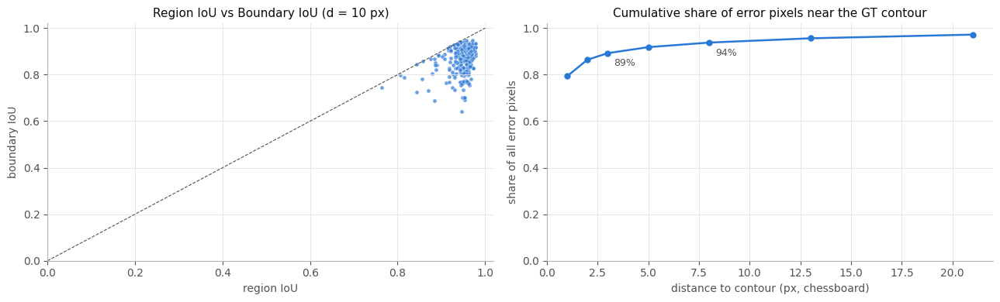

Mean region IoU 0.9470 vs mean Boundary IoU 0.8686 (d = 2% of the diagonal = 10 px)
Share of error pixels within k px of the GT contour: k=1: 79.3%, k=2: 86.4%, k=3: 89.2%, k=5: 91.8%, k=8: 93.8%, k=13: 95.6%, k=21: 97.2%


In [55]:
# 13.2 Boundary analysis ---------------------------------------------------------------------------------------------------------
def boundary_iou(gt: np.ndarray, pred: np.ndarray, d: int) -> float:
    g_band = gt & ~binary_erode(gt, d)
    p_band = pred & ~binary_erode(pred, d)
    union = (g_band | p_band).sum()
    return float((g_band & p_band).sum() / union) if union else float("nan")


DIST_BANDS = [1, 2, 3, 5, 8, 13, 21]


def boundary_width(shape) -> int:
    return max(1, int(round(CFG.boundary_width_fraction * math.hypot(*shape))))


D_TYPICAL = boundary_width((int(valid_df.img_h.median()), int(valid_df.img_w.median())))
err_within = np.zeros(len(DIST_BANDS))
err_total = 0
b_rows = []
for i in tqdm(split_idx["test"], desc="Boundary analysis", leave=False):
    i = int(i)
    g, p = test_store["gt"][i] > 0, test_store["pred"][i] > 0
    err = g ^ p
    contour = mask_boundary(g, 1)
    for j, k in enumerate(DIST_BANDS):
        err_within[j] += (err & binary_dilate(contour, k)).sum()
    err_total += err.sum()
    b_rows.append({"idx": i, "boundary_iou": boundary_iou(g, p, boundary_width(g.shape))})
boundary_df = pd.DataFrame(b_rows).merge(test_per_image[["idx", "iou", "dice"]], on="idx")
test_per_image = test_per_image.merge(boundary_df[["idx", "boundary_iou"]], on="idx", how="left")
err_share = err_within / max(err_total, 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(boundary_df["iou"], boundary_df["boundary_iou"], s=14, color=SERIES[0], alpha=0.7,
                edgecolors="white", linewidths=0.4)
axes[0].plot([0, 1], [0, 1], color=INK_2, linewidth=0.8, linestyle="--")
axes[0].set(title=f"Region IoU vs Boundary IoU (d = {D_TYPICAL} px)", xlabel="region IoU",
            ylabel="boundary IoU", xlim=(0, 1.02), ylim=(0, 1.02))
axes[1].plot(DIST_BANDS, err_share, color=SERIES[0], marker="o")
axes[1].set(title="Cumulative share of error pixels near the GT contour", xlabel="distance to contour (px, chessboard)",
            ylabel="share of all error pixels", ylim=(0, 1.02))
for x, y in zip(DIST_BANDS, err_share):
    if x in (3, 8):
        axes[1].annotate(f"{y:.0%}", (x, y), textcoords="offset points", xytext=(6, -12), fontsize=9, color=INK_2)
fig.tight_layout()
save_fig(fig, "error_boundary")
plt.show()
print(f"Mean region IoU {boundary_df.iou.mean():.4f} vs mean Boundary IoU {boundary_df.boundary_iou.mean():.4f} "
      f"(d = {CFG.boundary_width_fraction:.0%} of the diagonal = {D_TYPICAL} px)")
print("Share of error pixels within k px of the GT contour: "
      + ", ".join(f"k={k}: {s:.1%}" for k, s in zip(DIST_BANDS, err_share)))

### 13.3 Small-plant detection
Because the masks annotate the crop, the "small object" question here is how well **small (young or partly occluded) crop plants** are segmented. Weeds are the targets in the derived maps of Section 12.3, so the same scale sensitivity also bears on small-weed detection. Test images are grouped into quartiles of ground-truth foreground area.

,images,gt_fraction_mean,dice,iou,precision,recall
size_quartile,,,,,,
"(0.0144, 0.0534]",75,0.0348,0.9607,0.9252,0.9613,0.9614
"(0.0534, 0.0839]",75,0.0665,0.9741,0.9497,0.9680,0.9805
"(0.0839, 0.113]",75,0.0980,0.9758,0.9529,0.9723,0.9794
"(0.113, 0.366]",75,0.1691,0.9796,0.9601,0.9787,0.9806


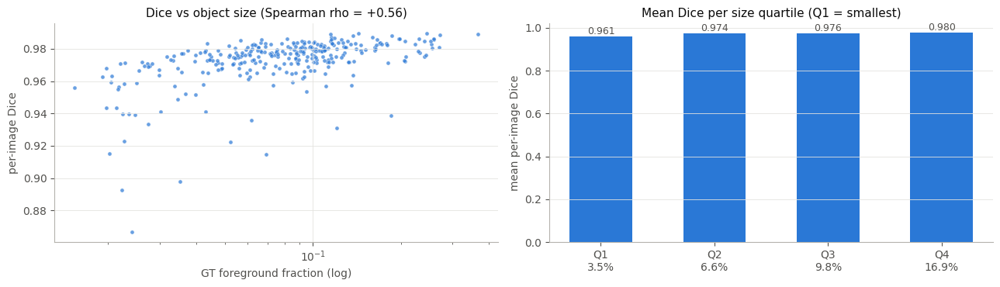

In [56]:
# 13.3 Performance as a function of object size ------------------------------------------------------------------------------------
def spearman(a, b) -> float:
    """Spearman rank correlation without SciPy (Pearson correlation of ranks)."""
    return float(pd.Series(np.asarray(a)).rank().corr(pd.Series(np.asarray(b)).rank()))


test_per_image["size_quartile"] = pd.qcut(test_per_image["gt_fraction"], q=4, duplicates="drop",
                                          labels=None).astype(str)
size_table = (test_per_image.groupby("size_quartile", observed=True)
              .agg(images=("idx", "size"), gt_fraction_mean=("gt_fraction", "mean"), dice=("dice", "mean"),
                   iou=("iou", "mean"), precision=("precision", "mean"), recall=("recall", "mean"))
              .sort_values("gt_fraction_mean"))
display(size_table.round(4))
size_table.to_csv(RESULTS_DIR / "error_by_object_size.csv")
rho_size = spearman(test_per_image.gt_fraction, test_per_image.dice)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(test_per_image.gt_fraction, test_per_image.dice, s=14, color=SERIES[0], alpha=0.7,
                edgecolors="white", linewidths=0.4)
axes[0].set_xscale("log")
axes[0].set(title=f"Dice vs object size (Spearman rho = {rho_size:+.2f})", xlabel="GT foreground fraction (log)",
            ylabel="per-image Dice")
axes[1].bar(range(len(size_table)), size_table["dice"], color=SERIES[0], width=0.55)
axes[1].set_xticks(range(len(size_table)), [f"Q{k + 1}\n{v:.1%}" for k, v in enumerate(size_table.gt_fraction_mean)])
axes[1].set(title="Mean Dice per size quartile (Q1 = smallest)", ylabel="mean per-image Dice",
            ylim=(0, 1.02))
axes[1].grid(axis="x", visible=False)
for k, v in enumerate(size_table["dice"]):
    axes[1].text(k, v + 0.01, f"{v:.3f}", ha="center", fontsize=9, color=INK_2)
fig.tight_layout()
save_fig(fig, "error_object_size")
plt.show()

### 13.4 Class imbalance
Imbalance shows up as a systematic **bias in predicted area**: a model dominated by the background under-segments (predicted foreground < ground truth, low recall), while an over-corrected model over-segments. The predicted vs true foreground fraction per image and the validation threshold sweep reveal which regime the model is in, and whether moving the operating point would help.

Mean signed area bias (predicted - true foreground fraction): +0.0005 (over-segmentation on average); median ratio predicted/true = 1.008
Dataset-level precision 0.9738 vs recall 0.9788


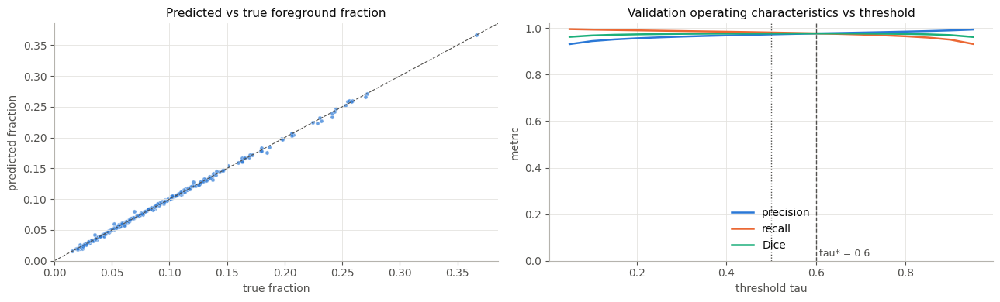

In [57]:
# 13.4 Imbalance diagnostics ---------------------------------------------------------------------------------------------------------
bias = test_per_image.pred_fraction - test_per_image.gt_fraction
print(f"Mean signed area bias (predicted - true foreground fraction): {bias.mean():+.4f} "
      f"({'over-segmentation' if bias.mean() > 0 else 'under-segmentation'} on average); "
      f"median ratio predicted/true = {(test_per_image.pred_fraction / test_per_image.gt_fraction.clip(lower=1e-9)).median():.3f}")
print(f"Dataset-level precision {test_overall['precision']:.4f} vs recall {test_overall['recall']:.4f}")

ncols = 2 if sweep is not None else 1
fig, axes = plt.subplots(1, ncols, figsize=(6.5 * ncols, 4))
axes = np.atleast_1d(axes)
lim = max(test_per_image.gt_fraction.max(), test_per_image.pred_fraction.max()) * 1.05
axes[0].scatter(test_per_image.gt_fraction, test_per_image.pred_fraction, s=14, color=SERIES[0], alpha=0.7,
                edgecolors="white", linewidths=0.4)
axes[0].plot([0, lim], [0, lim], color=INK_2, linestyle="--", linewidth=0.8)
axes[0].set(title="Predicted vs true foreground fraction", xlabel="true fraction", ylabel="predicted fraction",
            xlim=(0, lim), ylim=(0, lim))
if sweep is not None:
    for k, (col, name) in enumerate((("precision", "precision"), ("recall", "recall"), ("dice", "Dice"))):
        axes[1].plot(sweep.threshold, sweep[col], color=SERIES[k], label=name)
    axes[1].axvline(CFG.threshold, color=INK_2, linestyle=":", linewidth=1)
    axes[1].axvline(TAU_CAL, color=INK_2, linestyle="--", linewidth=1)
    axes[1].text(TAU_CAL, 0.02, f" tau* = {TAU_CAL}", color=INK_2, fontsize=9)
    axes[1].set(title="Validation operating characteristics vs threshold", xlabel="threshold tau",
                ylabel="metric", ylim=(0, 1.02))
    axes[1].legend(loc="lower center")
fig.tight_layout()
save_fig(fig, "error_class_imbalance")
plt.show()

### 13.5 Difficult lighting conditions
Two complementary analyses: (a) the **observational** relation between per-image brightness/contrast and Dice on the real test images, and (b) a **controlled robustness experiment** in which the brightness of every test image is scaled by a factor $\beta$ before inference ($\beta<1$ simulates under-exposure or overcast conditions, $\beta>1$ over-exposure). Training-time photometric augmentation covered $\beta\in[0.8, 1.2]$, so factors outside this range test extrapolation.

,images,brightness,dice,precision,recall
brightness_quartile,,,,,
"(0.489, 0.585]",75,0.5649,0.9733,0.9670,0.9799
"(0.585, 0.624]",75,0.6054,0.9696,0.9653,0.9747
"(0.624, 0.65]",75,0.6386,0.9712,0.9728,0.9701
"(0.65, 0.701]",75,0.6627,0.9761,0.9751,0.9772


Brightness x0.5:   0%|          | 0/38 [00:00<?, ?it/s]

Brightness x0.7:   0%|          | 0/38 [00:00<?, ?it/s]

Brightness x0.85:   0%|          | 0/38 [00:00<?, ?it/s]

Brightness x1.0:   0%|          | 0/38 [00:00<?, ?it/s]

Brightness x1.15:   0%|          | 0/38 [00:00<?, ?it/s]

Brightness x1.3:   0%|          | 0/38 [00:00<?, ?it/s]

Brightness x1.5:   0%|          | 0/38 [00:00<?, ?it/s]

,brightness_factor,dice,iou,precision,recall
0,0.50,0.8539,0.7451,0.9744,0.7600
1,0.70,0.9716,0.9448,0.9741,0.9692
2,0.85,0.9756,0.9523,0.9735,0.9776
3,1.00,0.9763,0.9537,0.9738,0.9788
4,1.15,0.9760,0.9530,0.9726,0.9793
5,1.30,0.9650,0.9324,0.9677,0.9623
6,1.50,0.6759,0.5105,0.9669,0.5196


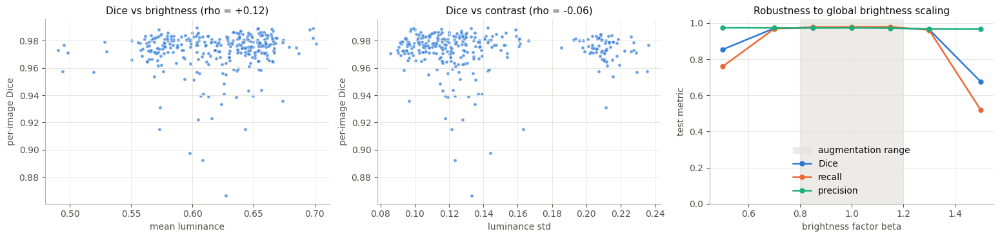

In [58]:
# 13.5 Illumination analysis + brightness robustness experiment --------------------------------------------------------------------------
rho_bright = spearman(test_per_image.brightness, test_per_image.dice)
rho_contr = spearman(test_per_image.contrast, test_per_image.dice)
test_per_image["brightness_quartile"] = pd.qcut(test_per_image.brightness, 4, duplicates="drop").astype(str)
display(test_per_image.groupby("brightness_quartile", observed=True)
        .agg(images=("idx", "size"), brightness=("brightness", "mean"), dice=("dice", "mean"),
             precision=("precision", "mean"), recall=("recall", "mean")).sort_values("brightness").round(4))

robust_df = None
if CFG.run_robustness_study:
    robust_rows = []
    for beta in CFG.brightness_factors:
        tf_beta = SegmentationTransform(IMG_SIZE, NORM_MEAN, NORM_STD, train=False, brightness_factor=beta)
        ds_beta = CWF788SegmentationDataset(ds_raw, split_idx["test"], IMAGE_COL, MASK_COL, tf_beta,
                                            return_native_mask=True)
        loader_beta = DataLoader(ds_beta, batch_size=CFG.batch_size, shuffle=False,
                                 collate_fn=collate_with_native, **LOADER_KW)
        ov, _, _, _ = evaluate_split(eval_model, loader_beta, CFG.threshold, desc=f"Brightness x{beta}")
        robust_rows.append({"brightness_factor": beta, **{k: ov[k] for k in ("dice", "iou", "precision", "recall")}})
    robust_df = pd.DataFrame(robust_rows)
    robust_df.to_csv(RESULTS_DIR / "robustness_brightness.csv", index=False)
    display(robust_df.round(4))

ncols = 3 if robust_df is not None else 2
fig, axes = plt.subplots(1, ncols, figsize=(5.2 * ncols, 3.8))
axes[0].scatter(test_per_image.brightness, test_per_image.dice, s=14, color=SERIES[0], alpha=0.7,
                edgecolors="white", linewidths=0.4)
axes[0].set(title=f"Dice vs brightness (rho = {rho_bright:+.2f})", xlabel="mean luminance", ylabel="per-image Dice")
axes[1].scatter(test_per_image.contrast, test_per_image.dice, s=14, color=SERIES[0], alpha=0.7,
                edgecolors="white", linewidths=0.4)
axes[1].set(title=f"Dice vs contrast (rho = {rho_contr:+.2f})", xlabel="luminance std", ylabel="per-image Dice")
if robust_df is not None:
    axes[2].axvspan(1 - CFG.brightness, 1 + CFG.brightness, color=GRID, alpha=0.7, label="augmentation range")
    axes[2].plot(robust_df.brightness_factor, robust_df.dice, color=SERIES[0], marker="o", label="Dice")
    axes[2].plot(robust_df.brightness_factor, robust_df.recall, color=SERIES[1], marker="o", label="recall")
    axes[2].plot(robust_df.brightness_factor, robust_df.precision, color=SERIES[2], marker="o", label="precision")
    axes[2].set(title="Robustness to global brightness scaling", xlabel="brightness factor beta", ylabel="test metric",
                ylim=(0, 1.02))
    axes[2].legend(loc="lower center")
fig.tight_layout()
save_fig(fig, "error_illumination")
plt.show()

### 13.6 Limitations of the model and possible improvements
**Methodological limitations**
- *Single training run.* Results come from one seed. The variance due to initialisation and data order is not estimated (see Future Work: repeated runs and k-fold cross-validation).
- *From-scratch training.* No pre-trained encoder is used, which limits the features that can be learned from 400 training images.
- *Fixed input resolution.* Down-sampling from 400 × 300 to 384 × 288 slightly reduces the detail available for thin structures. Up-sampling the logits restores the native geometry but not the lost information.
- *Binary supervision.* The labels distinguish crop from everything else. Weed maps are derived, not learned, and cannot be validated quantitatively.

**Improvements suggested by the analysis above** (to be prioritised according to the measured results):
1. *If false negatives dominate or recall falls on small plants:* use a lower calibrated threshold, Tversky or focal-Tversky losses (penalising FN more), multi-scale training or higher input resolution.
2. *If errors concentrate at contours:* use boundary-aware losses (boundary or Hausdorff-distance losses), test-time augmentation with flip averaging, or CRF / guided-filter refinement.
3. *If brightness sensitivity is high:* use wider photometric augmentation (gamma, hue/saturation, synthetic shadows), colour-constancy preprocessing, or an HSV / ExG auxiliary input channel.
4. *General:* a pre-trained encoder (e.g. ResNet-34 U-Net), attention gates (Attention U-Net), deep supervision, and post-processing that removes connected components smaller than a plausible plant.

In [60]:
# 13.6 Data-driven error summary ----------------------------------------------------------------------------------------------------------
err_summary = [
    f"- Dominant error type: **{'false negatives (crop missed)' if tot.fn > tot.fp else 'false positives (background labelled as crop)'}** "
    f"({max(tot.fn, tot.fp) / max(tot.fn + tot.fp, 1):.1%} of error pixels).",
    f"- **{err_share[DIST_BANDS.index(3)]:.1%}** of error pixels lie within 3 px of the ground-truth contour "
    f"(mean Boundary IoU {boundary_df.boundary_iou.mean():.3f} at d = {D_TYPICAL} px vs region IoU {boundary_df.iou.mean():.3f}).",
    f"- Size dependence: Spearman rho(object size, Dice) = **{rho_size:+.2f}**; mean Dice in the smallest-object "
    f"quartile = {size_table['dice'].iloc[0]:.3f} vs {size_table['dice'].iloc[-1]:.3f} in the largest.",
    f"- Area bias: {bias.mean():+.4f} (mean predicted - true foreground fraction).",
    f"- Illumination: rho(brightness, Dice) = {rho_bright:+.2f}, rho(contrast, Dice) = {rho_contr:+.2f}.",
]
if robust_df is not None:
    ref = robust_df.loc[np.isclose(robust_df.brightness_factor, 1.0), "dice"]
    ref = float(ref.iloc[0]) if len(ref) else float(test_overall["dice"])
    worst_beta = robust_df.loc[robust_df.dice.idxmin()]
    err_summary.append(f"- Brightness robustness: Dice ranges from {robust_df.dice.min():.3f} to {robust_df.dice.max():.3f} "
                       f"across beta in [{min(CFG.brightness_factors)}, {max(CFG.brightness_factors)}]; the lowest value "
                       f"({ref - worst_beta.dice:.3f} below beta = 1) occurs at beta = {worst_beta.brightness_factor}.")
display(Markdown("\n".join(err_summary)))
test_per_image.to_csv(RESULTS_DIR / "per_image_test_metrics.csv", index=False)

- Dominant error type: **false positives (background labelled as crop)** (55.4% of error pixels).
- **89.2%** of error pixels lie within 3 px of the ground-truth contour (mean Boundary IoU 0.869 at d = 10 px vs region IoU 0.947).
- Size dependence: Spearman rho(object size, Dice) = **+0.56**; mean Dice in the smallest-object quartile = 0.961 vs 0.980 in the largest.
- Area bias: +0.0005 (mean predicted - true foreground fraction).
- Illumination: rho(brightness, Dice) = +0.12, rho(contrast, Dice) = -0.06.
- Brightness robustness: Dice ranges from 0.676 to 0.976 across beta in [0.5, 1.5]; the lowest value (0.300 below beta = 1) occurs at beta = 1.5.

---
## 14. Scientific Discussion

### 14.1 Computational complexity (measured)

In [61]:
# 14.1 Measured complexity: parameters, FLOPs, latency, memory ------------------------------------------------------------------------------
@torch.inference_mode()
def measure_latency(net, batch_size: int, n_warmup: int = 3, n_iter: int = 10) -> float:
    x = torch.randn(batch_size, 3, *IMG_SIZE, device=DEVICE)
    net.eval()
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
        for _ in range(n_warmup):
            net(x)
        if USE_CUDA:
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            net(x)
        if USE_CUDA:
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_iter


lat_1 = measure_latency(eval_model, 1)
lat_b = measure_latency(eval_model, CFG.batch_size)
complexity = {
    "device": str(DEVICE) + (f" ({torch.cuda.get_device_name(0)})" if USE_CUDA else f" ({platform.processor() or platform.machine()})"),
    "base filters": CFG.base_filters,
    "trainable parameters": f"{trainable_params:,}",
    "GFLOPs per image (forward)": round(gflops, 2),
    "weights size (MiB, float32)": round(model_mb, 2),
    "checkpoint file size (MiB, incl. optimiser state)": round(ckpt_path.stat().st_size / 1024 ** 2, 2),
    "latency, batch 1 (ms/image)": round(lat_1 * 1000, 2),
    f"throughput, batch {CFG.batch_size} (images/s)": round(CFG.batch_size / lat_b, 2),
    "mean training time per epoch (s)": round(training_summary["mean_epoch_time_s"], 2),
    "cumulative training time (min)": round(training_summary["total_training_time_s"] / 60, 2),
    "peak GPU memory allocated (GiB)": round(torch.cuda.max_memory_allocated() / 1024 ** 3, 2) if USE_CUDA else "n/a",
}
display(pd.Series(complexity, name="value").to_frame())
_ = (RESULTS_DIR / "complexity.json").write_text(json.dumps({k: str(v) for k, v in complexity.items()}, indent=2))

,value
device,cuda (Tesla T4)
base filters,64
trainable parameters,"31,037,633"
GFLOPs per image (forward),162.56
"weights size (MiB, float32)",118.4
"checkpoint file size (MiB, incl. optimiser state)",355.34
"latency, batch 1 (ms/image)",22.86
"throughput, batch 8 (images/s)",70.55
mean training time per epoch (s),20.37
cumulative training time (min),13.58


### 14.2 Generalisation
Generalisation is judged by comparing the validation split (used for model selection) with the untouched test split under the **identical** native-resolution protocol. A small validation–test difference indicates that model selection did not overfit the validation images. The training-set Dice is shown for reference only, because it is measured on augmented images.

In [62]:
# 14.2 Generalisation summary ------------------------------------------------------------------------------------------------------------------
best_hist = hist.loc[hist.epoch == best_epoch].iloc[0]
gen_table = pd.DataFrame({
    "Dice": [best_hist.train_dice, val_overall["dice"], test_overall["dice"]],
    "IoU": [best_hist.train_iou, val_overall["iou"], test_overall["iou"]],
    "protocol": ["augmented batches, model resolution (epoch of selection)", "native resolution, tau = 0.5",
                 "native resolution, tau = 0.5"],
}, index=["train", "validation", "test"])
display(gen_table.round(4))
print(f"Validation - test Dice difference: {val_overall['dice'] - test_overall['dice']:+.4f}")

,Dice,IoU,protocol
train,0.9689,0.9396,"augmented batches, model resolution (epoch of ..."
validation,0.9772,0.9554,"native resolution, tau = 0.5"
test,0.9763,0.9537,"native resolution, tau = 0.5"


Validation - test Dice difference: +0.0009


### 14.3 Discussion

**U-Net performance.** The final results table (Section 11.5) reports the U-Net on the official, held-out test split, scored at native resolution against unmodified masks. Two reference points frame these numbers. First, the *trivial all-background predictor* reaches high pixel accuracy but a Dice of zero (Section 4.4), which is why pixel accuracy is not the headline metric. Second, the *ExG + Otsu baseline* is evaluated on identical masks. Because it labels every green pixel as crop, its precision directly measures how much non-crop vegetation the images contain. The gap between U-Net and baseline precision measures the discriminative ability that convolutional shape and texture features add beyond colour. The per-image distribution (mean ± std, best/median/worst examples) shows whether performance is uniform or driven by a subset of hard images.

**Generalisation.** The validation and test splits come from the same two acquisition sessions and the same field site, so the test score measures *in-distribution* generalisation (Section 14.2). It says nothing about other fields, crops, cameras or growth stages. Cross-dataset evaluation, for instance on other AgML crop–weed datasets, would be needed for any claim of out-of-domain robustness. The controlled brightness experiment (Section 13.5) is a first, partial probe of robustness to distribution shift.

**Computational complexity.** U-Net has $O(HW)$ cost per image, with most FLOPs spent in the full-resolution decoder stages. Parameter count, FLOPs, latency and memory were measured in Section 14.1 on the hardware actually used. Real-time operation on a sprayer requires the per-image latency to fit within the camera frame budget at the vehicle's travel speed. If it does not, halving `base_filters` divides FLOPs and parameters by roughly four. Mixed-precision or INT8 inference on embedded GPUs, and pruning, are the usual next steps.

**Dataset limitations.** CWF-788 contains one crop species (cauliflower), two acquisition days, one location, three consumer cameras, a nadir viewpoint and 788 images. The annotation is crop-only, without weed instances or species, and the authors report contour-based polygon labelling, which bounds achievable boundary accuracy. Images are generally centred on one crop plant (Section 4.3), unlike the continuous row imagery a moving vehicle would capture. The Hub version omits acquisition metadata such as date and device, so lighting effects can only be studied through image-statistics proxies.

**Practical agricultural applications.** A crop mask directly supports (i) *selective spraying*: treat vegetation outside the dilated crop mask, as in the derived weed maps of Section 12.3; (ii) *mechanical intra-row weeding*: the crop mask defines a protection zone for hoes or tines; (iii) *crop monitoring*: per-plant canopy area as a growth indicator; and (iv) *weed-pressure mapping*: aggregating the estimated weed cover per image along GPS tracks. The measured crop-protection error (Section 12.3) translates segmentation errors into the agronomically meaningful quantity "share of crop tissue that would be treated".

**Relation to other segmentation approaches.** Other architectures used for crop–weed segmentation include FCN (Long *et al.*, 2015), SegNet, DeepLab-v3+ (atrous convolutions and pyramid pooling) and transformer-based models such as SegFormer. The original CWF-788 study (Li *et al.*, 2019) uses a saliency-detection network with short connections and adaptive affinity fields. **None of these models was trained or evaluated in this project.** The only comparison claimed here is with the ExG + Otsu baseline, which was run on the same data. A fair comparison with other architectures would require running them under the identical protocol: same splits, resolution, augmentation, training budget, native-resolution scoring and several seeds.

---
## 15. Conclusion and Future Work

### 15.1 Scientific summary (generated from this run's results)

In [66]:
# 15.1 Auto-generated scientific summary ------------------------------------------------------------------------------------------------------
summary = {
    "dataset": {"id": CFG.dataset_id, "valid_samples": int(len(valid_df)), "excluded": n_bad, "task": TASK,
                "num_classes": int(NUM_CLASSES), "class_names": CLASS_NAMES, "partition_source": PARTITION_SOURCE,
                "split_sizes": {k: int(len(v)) for k, v in split_idx.items()}, "train_fg_share": fg_share},
    "training": training_summary,
    "test_primary": test_overall,
    "test_calibrated": test_cal_overall, "tau_calibrated": TAU_CAL,
    "baseline_exg_otsu": baseline_overall,
    "validation_native": val_overall,
    "boundary": {"mean_boundary_iou": float(boundary_df.boundary_iou.mean()),
                 "error_share_within_3px": float(err_share[DIST_BANDS.index(3)])},
    "size_spearman": rho_size, "brightness_spearman": rho_bright,
    "robustness": None if robust_df is None else robust_df.to_dict(orient="list"),
    "weed_map": None if weed_df is None else {"mean_est_weed_cover": float(weed_df.est_weed_cover.mean()),
                                               "mean_crop_targeted_share": float(weed_df.crop_targeted_share.mean())},
}
_ = (RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float))

txt = [
    f"**Experiment.** A U-Net ({trainable_params / 1e6:.1f} M parameters, base width {CFG.base_filters}) was trained from scratch "
    f"for {training_summary['epochs_completed']} epochs ({training_summary['total_training_time_s'] / 60:.1f} min on {DEVICE.type.upper()}) "
    f"on {len(split_idx['train'])} CWF-788 training images for **{TASK}** segmentation ({', '.join(CLASS_NAMES)}), "
    f"using the {PARTITION_SOURCE}. The model selected on validation Dice (epoch {best_epoch}) was evaluated once on "
    f"{len(split_idx['test'])} held-out test images at native resolution.",
    f"**Main result.** Test Dice = **{test_overall['dice']:.4f}**, IoU = **{test_overall['iou']:.4f}**, precision = "
    f"{test_overall['precision']:.4f}, recall = {test_overall['recall']:.4f}, F1 = {test_overall['f1']:.4f}, pixel accuracy = "
    f"{test_overall['pixel_accuracy']:.4f} (per-image Dice {test_per_image.dice.mean():.4f} ± {test_per_image.dice.std(ddof=1):.4f}).",
]
if baseline_overall is not None:
    txt.append(f"**Learned vs colour-based.** The ExG + Otsu baseline reached Dice {baseline_overall['dice']:.4f} "
               f"(precision {baseline_overall['precision']:.4f}, recall {baseline_overall['recall']:.4f}). The U-Net "
               f"{'improves' if test_overall['dice'] > baseline_overall['dice'] else 'does not improve'} Dice by "
               f"{test_overall['dice'] - baseline_overall['dice']:+.4f} and precision by "
               f"{test_overall['precision'] - baseline_overall['precision']:+.4f}, which quantifies the value of learned "
               "shape/context features for separating crop from weeds of similar colour.")
if TAU_CAL is not None:
    txt.append(f"**Operating point.** A validation-calibrated threshold tau* = {TAU_CAL} gives test Dice "
               f"{test_cal_overall['dice']:.4f} ({test_cal_overall['dice'] - test_overall['dice']:+.4f} vs tau = {CFG.threshold}).")
txt.append(f"**Generalisation.** Validation Dice {val_overall['dice']:.4f} vs test Dice {test_overall['dice']:.4f} "
           f"(difference {val_overall['dice'] - test_overall['dice']:+.4f}) under the same protocol.")
txt.append("**Error structure.** " + " ".join(s.lstrip("- ") for s in err_summary))
if weed_df is not None:
    txt.append(f"**Weed maps.** Derived weed maps estimate a mean weed cover of {weed_df.est_weed_cover.mean():.1%} of the image "
               f"area (unvalidated indicator); on average {weed_df.crop_targeted_share.mean():.2%} of true crop pixels would be "
               "wrongly targeted (crop-protection error).")
display(Markdown("\n\n".join(txt)))

**Experiment.** A U-Net (31.0 M parameters, base width 64) was trained from scratch for 40 epochs (13.6 min on CUDA) on 400 CWF-788 training images for **binary** segmentation (background (soil + weeds), crop (cauliflower)), using the official partition provided with the dataset. The model selected on validation Dice (epoch 40) was evaluated once on 300 held-out test images at native resolution.

**Main result.** Test Dice = **0.9763**, IoU = **0.9537**, precision = 0.9738, recall = 0.9788, F1 = 0.9763, pixel accuracy = 0.9956 (per-image Dice 0.9725 ± 0.0150).

**Learned vs colour-based.** The ExG + Otsu baseline reached Dice 0.2317 (precision 0.1414, recall 0.6396). The U-Net improves Dice by +0.7447 and precision by +0.8324, which quantifies the value of learned shape/context features for separating crop from weeds of similar colour.

**Operating point.** A validation-calibrated threshold tau* = 0.6 gives test Dice 0.9761 (-0.0002 vs tau = 0.5).

**Generalisation.** Validation Dice 0.9772 vs test Dice 0.9763 (difference +0.0009) under the same protocol.

**Error structure.** Dominant error type: **false positives (background labelled as crop)** (55.4% of error pixels). **89.2%** of error pixels lie within 3 px of the ground-truth contour (mean Boundary IoU 0.869 at d = 10 px vs region IoU 0.947). Size dependence: Spearman rho(object size, Dice) = **+0.56**; mean Dice in the smallest-object quartile = 0.961 vs 0.980 in the largest. Area bias: +0.0005 (mean predicted - true foreground fraction). Illumination: rho(brightness, Dice) = +0.12, rho(contrast, Dice) = -0.06. Brightness robustness: Dice ranges from 0.676 to 0.976 across beta in [0.5, 1.5]; the lowest value (0.300 below beta = 1) occurs at beta = 1.5.

**Weed maps.** Derived weed maps estimate a mean weed cover of 35.1% of the image area (unvalidated indicator); on average 0.18% of true crop pixels would be wrongly targeted (crop-protection error).

### 15.2 Limitations
1. **Single-site, single-crop data.** Conclusions apply to transplanted cauliflower under the CWF-788 acquisition conditions. Transfer to other crops, soils, growth stages or camera set-ups is untested.
2. **Crop-only annotation.** Weed segmentation is obtained indirectly, so weed-level precision and recall cannot be measured.
3. **Statistical uncertainty.** One training run and one data partition. Without repeated runs, differences of the order of a few thousandths in Dice should not be over-interpreted.
4. **Resolution and annotation granularity.** Released images are 400 × 300 pixels and annotations are polygonal. Fine leaf structures and boundary accuracy are bounded by both.
5. **Proxy lighting analysis.** Without acquisition metadata, illumination effects are inferred from image statistics and from synthetic brightness scaling.

### 15.3 Future research directions
1. **Multi-class crop / weed / soil annotation**, ideally with weed species, to learn weed segmentation directly and validate weed maps quantitatively.
2. **Statistical robustness:** k-fold cross-validation and ≥ 5 seeds, with confidence intervals (e.g. bootstrap over test images) and paired significance tests between models.
3. **Controlled architecture study** under the identical protocol: pre-trained encoders (ResNet / EfficientNet U-Net), Attention U-Net, U-Net++, DeepLab-v3+, SegFormer.
4. **Imbalance- and boundary-aware objectives** (Tversky, focal, boundary losses), plus test-time augmentation.
5. **Domain generalisation:** cross-dataset training and testing on other AgML crop–weed datasets; colour-constancy and illumination-invariant inputs (ExG, HSV, near-infrared where available).
6. **Deployment:** INT8 quantisation, TensorRT/ONNX export, and latency benchmarks on embedded GPUs (e.g. NVIDIA Jetson) at field-relevant frame rates, closing the loop with a sprayer or weeder simulator.

### 15.4 Generated artefacts

In [67]:
# 15.4 Inventory of generated files ------------------------------------------------------------------------------------------------------------
inventory = []
for folder in (CKPT_DIR, RESULTS_DIR, FIG_DIR):
    for f in sorted(folder.glob("*")):
        if f.is_file():
            inventory.append({"folder": str(folder.relative_to(ROOT)), "file": f.name,
                              "size (KiB)": round(f.stat().st_size / 1024, 1)})
display(pd.DataFrame(inventory))
print("Final results table:", RESULTS_DIR / "final_results_table.md")

,folder,file,size (KiB)
0,checkpoints/unet_cwf788,best.pt,363869.1
1,checkpoints/unet_cwf788,last.pt,363869.1
2,results/unet_cwf788,complexity.json,0.5
3,results/unet_cwf788,config.json,1.1
4,results/unet_cwf788,dataset_scan.csv,102.6
5,results/unet_cwf788,derived_weed_maps.csv,18.7
6,results/unet_cwf788,error_by_object_size.csv,0.5
7,results/unet_cwf788,final_results_table.csv,0.7
8,results/unet_cwf788,final_results_table.md,0.5
9,results/unet_cwf788,normalisation.json,0.2


Final results table: /kaggle/working/results/unet_cwf788/final_results_table.md


---
**Reproducibility statement.** All results in this notebook were produced by the code above with the configuration saved in `results/<run>/config.json`, the software versions in `results/<run>/software_versions.json`, and the data partition in `results/<run>/partition.json`. Training can be resumed or audited from `checkpoints/<run>/last.pt`. Exact bit-wise reproducibility across different GPUs, drivers or library versions is not guaranteed by PyTorch. On the same hardware and software stack, the protocol is deterministic up to the GPU operations flagged by PyTorch as non-deterministic.

*Dataset citation:* Li, N., Zhang, X., Zhang, C., Guo, H., Sun, Z., Wu, X. (2019). Real-time crop recognition in transplanted fields with prominent weed growth: a visual-attention-based approach. *IEEE Access*, 7, 185310–185321. Distributed on the Hugging Face Hub by the AgML project (https://project-agml.github.io/).